# 🧪 الأعمال التطبيقية 3 (TP3): التصنيف الخاضع للإشراف — بيانات تشخيص سرطان الثدي
### عمل مخبري أكاديمي | الفصل الرابع: التصنيف (Chapter IV: Classification)
**المادة:** التعلّم الآلي والتعرّف الإحصائي على الأنماط (Machine Learning & Statistical Pattern Recognition)  
**بيئة العمل:** متوافق بالكامل مع Google Colab و VS Code  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/saoula2026/ml_univ/blob/main/TP3/breast_cancer_dataset/TP3_Breast_Cancer_Arabic.ipynb)

---

## 🎯 أهداف العمل التطبيقي ومحتوى المقرر
في هذا العمل التطبيقي (**TP3**)، نُجري دراسة تجريبية ونظرية شاملة ومعمقة لـ **11 خوارزمية تصنيف أساسية** تمت دراستها في **الفصل الرابع: التصنيف (Chapter IV: Classification)**:

1. **الانحدار اللوجستي (Logistic Regression)** (دالة السيجمويد والإنتروبيا المتقاطعة الثنائية)
2. **الانحدار اللوجستي متعدد الحدود (Polynomial Logistic Regression)** (التوسع في فضاء الخصائص غير الخطي)
3. **البيرسبترون البسيط (Simple Perceptron)** (وحدة العتبة الخطية لروزنبلات)
4. **البيرسبترون متعدد الطبقات (Multi-Layer Perceptron - MLP)** (الشبكات العصبية مع الانتشار العكسي)
5. **شجرة القرار باستخدام كسب المعلومات (Decision Tree - Entropy)** (تقليص إنتروبيا شانون)
6. **شجرة القرار باستخدام شوائب جيني (Decision Tree - Gini Impurity)** (مقياس تباين توزيع الفئات)
7. **الغابة العشوائية (Random Forest Classifier)** (تجميع العينات العشوائية والفضاءات الجزئية للخصائص)
8. **خوارزمية الجيران الأقرب ($k$-NN - K-Nearest Neighbors)** (التعلم القائم على مقياس المسافة الإقليدية)
9. **نايف بايز الغاوسي (Gaussian Naive Bayes)** (النمذجة الاحتمالية بافتراض الاستقلالية الشرطية)
10. **آلة المتجهات الداعمة الخطية (Linear SVM)** (تعظيم الهامش الهندسي الفاصل)
11. **آلة المتجهات الداعمة غير الخطية (Non-Linear SVM - RBF Kernel)** (الإسقاط في فضاء هيلبرت عبر نواة RBF)

### المخطط المنهجي المتبع:
* **القسم 1: استكشاف وتحليل البيانات (EDA):** فحص الخصائص المورفولوجية، وتوزيع الفئات، وتحليل الارتباط والتشتت.
* **القسم 2: معالجة البيانات واستراتيجية التحقق:** معالجة التعددية الخطية، والتقسيم الطبقي للبيانات (Stratified Hold-out)، والمعايرة القياسية بدون تسريب للبيانات.
* **القسم 3: التدريب والصياغة الرياضية والتقييم الشامل لكل نموذج:** تقديم النظريات والمعادلات، والتدريب مع التحقق المتقاطع الخماسي الطبقي (5-Fold Stratified CV)، ورسم مصفوفة الالتباس ومنحنى ROC لكل خوارزمية.
* **القسم 4: ضبط المعاملات الفائقة (Hyperparameter Optimization):** استخدام البحث الشبكي (`GridSearchCV`) لتحسين أداء النماذج الأساسية.
* **القسم 5: المقارنة النهائية والاستنتاج الأكاديمي:** جدول مقارنة تركيبي شامل مع تظليل النتائج المثلى، ورسوم بيانية مقارنة، وتحليل معمق لخصائص البيانات وسلوك النماذج.

In [1]:
# ==============================================================================
# القسم 0: إعداد بيئة العمل واستيراد المكتبات البرمجية
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

# مكتبات الحساب العلمي ومعالجة البيانات
import numpy as np
import pandas as pd

# مكتبات الرسم البياني والتمثيل المرئي
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# ضبط عارض Plotly ليتوافق مع VS Code و Google Colab
pio.renderers.default = "notebook_connected"

# Scikit-Learn: البيانات والتحقق المتقاطع
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline

# Scikit-Learn: نماذج التصنيف الـ 11
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Scikit-Learn: مقاييس تقييم الأداء
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    classification_report
)

# الإعدادات العامة لجماليات الرسوم البيانية
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14

# تثبيت البذرة العشوائية لضمان إمكانية إعادة إنتاج النتائج
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✅ تم استيراد جميع المكتبات المطلوبة بنجاح.")
print(f"📊 إصدار NumPy: {np.__version__}")
print(f"🐼 إصدار Pandas: {pd.__version__}")

✅ تم استيراد جميع المكتبات المطلوبة بنجاح.
📊 إصدار NumPy: 2.4.6
🐼 إصدار Pandas: 3.0.3


## 1. تحميل واستكشاف البيانات (Data Loading & EDA)

تُعتبر مجموعة بيانات **سرطان الثدي ويسكونسن التشخيصية (Breast Cancer Wisconsin Diagnostic)** من أشهر المجموعات القياسية في مجال التصنيف الطبي الحيوي (Wolberg et al., 1995).

تم حساب الخصائص انطلاقاً من صور مجهرية رقمية لخزعات الإبرة الدقيقة (Fine-Needle Aspirate - FNA) لكتل نسيج الثدي، حيث تصف السمات الهندسية لنوى الخلايا:
* **عدد العينات:** 569 عينة مريض.
* **عدد الخصائص:** 30 خاصية رقمية مستمرة ناتجة عن 10 سمات مورفولوجية أساسية مقاسة عبر 3 أبعاد إحصائية: **المتوسط (Mean)**، **الخطأ المعياري (SE)**، و**الأسوأ / القيمة القصوى (Worst)**:
  1. *نصف القطر (Radius)*
  2. *الملمس (Texture)* (الانحراف المعياري لدرجات الرمادي)
  3. *المحيط (Perimeter)*
  4. *المساحة (Area)*
  5. *النعومة (Smoothness)*
  6. *التراص (Compactness)*
  7. *التقعر (Concavity)* (شدة الأجزاء المقعرة من المحيط)
  8. *النقاط المقعرة (Concave points)*
  9. *التناظر (Symmetry)*
  10. *البعد الكسوري (Fractal dimension)*
* **الفئات المستهدفة:** تشخيص ثنائي (Binary Diagnosis):
  * `0`: **ورم خبيث (Malignant)** — (خلايا سرطانية / خطورة سريرية عالية)
  * `1`: **ورم حميد (Benign)** — (خلايا غير سرطانية / آمنة)

In [2]:
# تحميل مجموعة البيانات مباشرة من Scikit-Learn
raw_data = load_breast_cancer(as_frame=True)
df = raw_data.frame.copy()

# إضافة عمود التسمية النصية القابلة للقراءة
df['diagnosis'] = df['target'].map({0: 'Malignant (خبيث)', 1: 'Benign (حميد)'})

# عرض أبعاد وهيكل البيانات
print(f"أبعاد البيانات: {df.shape[0]} صفاً، {df.shape[1]} عموداً (30 خاصية + الفئة الرقمية + التسمية التشخيصية)")
df.head(10)

أبعاد البيانات: 569 صفاً، 32 عموداً (30 خاصية + الفئة الرقمية + التسمية التشخيصية)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant (خبيث)
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant (خبيث)
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant (خبيث)
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant (خبيث)
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant (خبيث)
5,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,...,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,0,Malignant (خبيث)
6,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,...,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,0,Malignant (خبيث)
7,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,0.07451,...,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510,0,Malignant (خبيث)
8,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,...,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,0,Malignant (خبيث)
9,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,0.08243,...,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750,0,Malignant (خبيث)


In [3]:
# معلومات موجزة حول أنواع البيانات والقيم المفقودة
print("--- معلومات إطار البيانات (Dataframe Info) ---")
df.info()

print("\n--- فحص القيم المفقودة (Missing Values) ---")
missing_counts = df.isnull().sum()
print(f"إجمالي القيم المفقودة في كافة الخلايا: {missing_counts.sum()}")

print("\n--- فحص الصفوف المكررة (Duplicate Rows) ---")
duplicate_count = df.duplicated().sum()
print(f"إجمالي الصفوف المكررة: {duplicate_count}")

--- معلومات إطار البيانات (Dataframe Info) ---
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    flo

In [4]:
# الإحصاءات الوصفية للخصائص الرقمية (أول 10 خصائص)
df.drop(columns=['target', 'diagnosis']).describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']].head(10)

,mean,std,min,25%,50%,75%,max
mean radius,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


--- توزيع فئات التشخيص ---


,العدد (Count),النسبة المئوية (%)
diagnosis,,
Benign (حميد),357,62.74
Malignant (خبيث),212,37.26


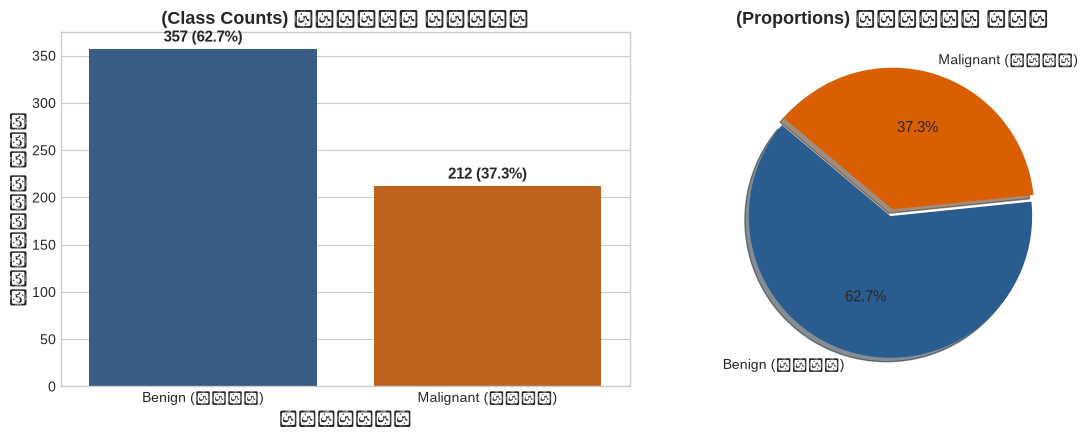

In [5]:
# تحليل توازن الفئات المستهدفة (Class Distribution)
class_counts = df['diagnosis'].value_counts()
class_percentages = df['diagnosis'].value_counts(normalize=True) * 100

class_summary = pd.DataFrame({
    'العدد (Count)': class_counts,
    'النسبة المئوية (%)': class_percentages.round(2)
})
print("--- توزيع فئات التشخيص ---")
display(class_summary)

# رسم بياني لتوزيع الفئات
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# مخطط الأعمدة
sns.barplot(x=class_summary.index, y=class_summary['العدد (Count)'], palette=['#2b5c8f', '#d95f02'], ax=axes[0])
axes[0].set_title("تكرار الفئات (Class Counts)", fontweight='bold')
axes[0].set_ylabel("عدد العينات")
axes[0].set_xlabel("التشخيص")
for i, count in enumerate(class_summary['العدد (Count)']):
    axes[0].text(i, count + 8, f"{count} ({class_percentages.iloc[i]:.1f}%)", ha='center', fontweight='bold')

# المخطط الدائري
axes[1].pie(
    class_counts,
    labels=class_counts.index,
    autopct='%1.1f%%',
    colors=['#2b5c8f', '#d95f02'],
    startangle=140,
    explode=[0.05, 0],
    shadow=True
)
axes[1].set_title("نسب الفئات (Proportions)", fontweight='bold')

plt.tight_layout()
plt.show()

In [6]:
# مخطط تشتت تفاعلي (Plotly Express)
fig_eda = px.scatter(
    df,
    x='mean radius',
    y='mean texture',
    color='diagnosis',
    color_discrete_map={'Malignant (خبيث)': '#d95f02', 'Benign (حميد)': '#2b5c8f'},
    size='mean area',
    hover_data=['mean perimeter', 'mean smoothness', 'mean concavity'],
    title="تحليل استكشافي تفاعلي: نصف القطر مقابل الملمس (حجم النقطة يمثل المساحة)",
    labels={'mean radius': 'متوسط نصف القطر (Mean Radius)', 'mean texture': 'متوسط الملمس (Mean Texture)'},
    template='plotly_white',
    marginal_x='box',
    marginal_y='box'
)
fig_eda.update_layout(width=900, height=550)
fig_eda.show()

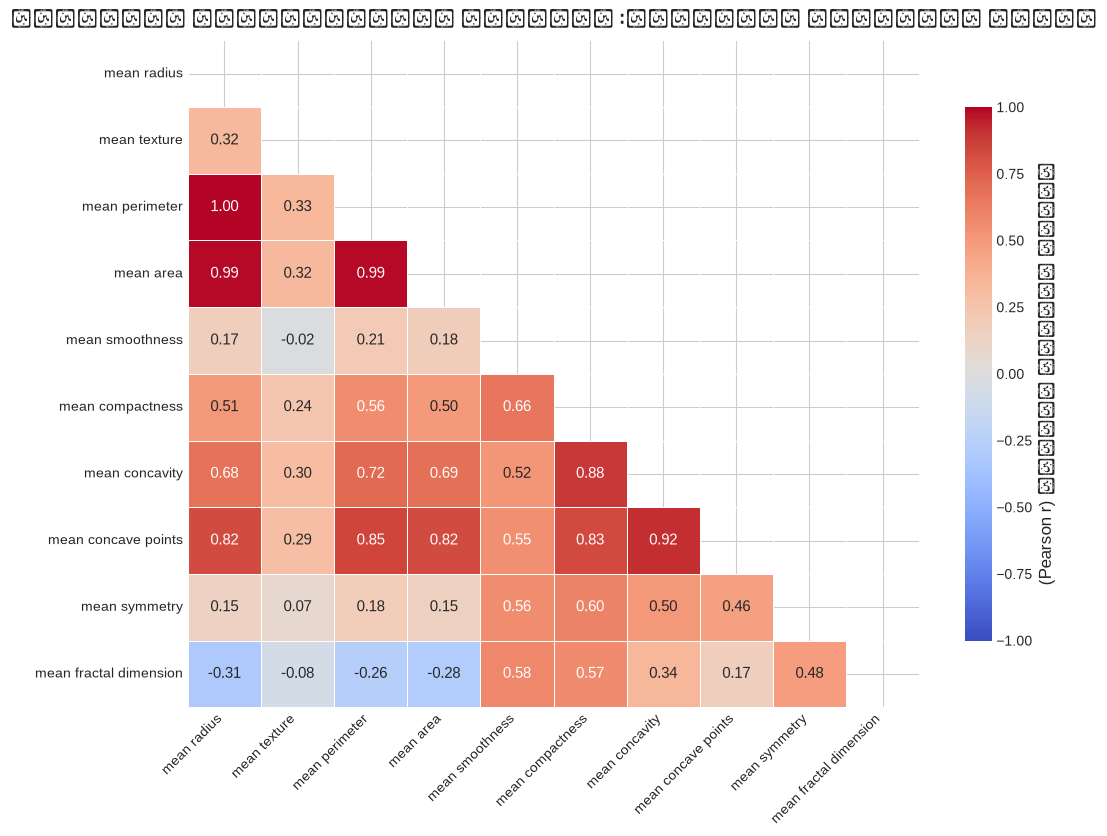

In [7]:
# خريطة الارتباط الحرارية للخصائص المورفولوجية
features_only = df.drop(columns=['target', 'diagnosis'])
corr_matrix = features_only.corr()

# التركيز على الخصائص الـ 10 الخاصة بالمتوسط لعرض أكاديمي واضح
mean_features = [col for col in features_only.columns if col.startswith('mean ')]
mean_corr = features_only[mean_features].corr()

plt.figure(figsize=(11, 8.5))
mask = np.triu(np.ones_like(mean_corr, dtype=bool))
sns.heatmap(
    mean_corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "معامل ارتباط بيرسون (Pearson r)"}
)
plt.title("خريطة الارتباط الحرارية: الخصائص المورفولوجية المتوسطة", fontsize=14, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

> [!NOTE]
> ### 🔍 أهم الملاحظات المستخلصة من التحليل الاستكشافي والارتباط الخطي:
> 1. **الارتباط الخطي القوي بين الخصائص (Extreme Collinearities):**
>    * نلاحظ ارتباطاً خطياً شبه تام ($r > 0.95$) بين الخصائص المعبرة عن الحجم والأبعاد:
>      * `mean radius` $\leftrightarrow$ `mean perimeter` ($r = 0.998$)
>      * `mean radius` $\leftrightarrow$ `mean area` ($r = 0.987$)
>      * `mean perimeter` $\leftrightarrow$ `mean area` ($r = 0.987$)
>      * `mean concavity` $\leftrightarrow$ `mean concave points` ($r = 0.921$)
> 2. **التداعيات المنهجية على سلوك الخوارزميات:**
>    * **النماذج الخطية (الانحدار اللوجستي، SVM الخطي، البيرسبترون):** لا يؤثر الارتباط سلباً على دقة التنبؤ الإجمالية، ولكنه يضخم تباين الأوزان التقديرية، مما يؤكد ضرورة استخدام التنظيم ($L_2$ Regularization).
>    * **نايف بايز (Naive Bayes):** ينتهك فرضية الاستقلالية الشرطية الصارمة $P(X|Y) = \prod P(X_j|Y)$، حيث يتكرر احتساب المعلومات المورفولوجية ذاتها عدة مرات.
>    * **النماذج الشجرية (أشجار القرار، الغابة العشوائية):** منيعة تماماً ضد الارتباط الخطي لأن عملية التقسيم تقيم بعداً واحداً في كل خطوة.

## 2. معالجة البيانات واستراتيجية التحقق (Data Preprocessing)

### 2.1 تحليل التعددية الخطية واستراتيجية الاحتفاظ بالخصائص
في خطوط الإنتاج الهندسية، يمكن استبعاد الخصائص المتكررة التي يتجاوز ارتباطها $|r| > 0.95$. في هذا العمل التطبيقي، نستعرض الأزواج شديدة الارتباط، مع الاحتفاظ بجميع الخصائص الـ 30 لدراسة سلوك النماذج المختلفة (كالنماذج المنظمة والنماذج المعتمدة على المسافات) تجريبياً في ظل وجود هذا الارتباط.

### 2.2 ترميز الفئات (Target Encoding)
* الفئة `0`: **ورم خبيث (Malignant)**
* الفئة `1`: **ورم حميد (Benign)**

### 2.3 استراتيجية التقسيم الطبقي للبيانات (الفصل الرابع، القسم 9)
بناءً على ما ورد في **القسم 9 من الفصل الرابع** حول استراتيجيات التحقق، تتطلب التجربة تقسيماً غير متحيز للبيانات:
$$\mathcal{D} = \mathcal{D}_{\text{train}} \cup \mathcal{D}_{\text{test}}, \quad \mathcal{D}_{\text{train}} \cap \mathcal{D}_{\text{test}} = \emptyset$$
* **التقسيم الطبقي (Stratified Splitting):** نظراً لعدم التساوي التام بين الفئتين (62.7% أورام حميدة مقابل 37.3% خبيثة)، فإن التقسيم الطبقي (`stratify=y`) يحافظ بدقة على نسبة الفئات الأصلية في كل من مجموعة التدريب (80%) ومجموعة الاختبار (20%).

### 2.4 المعايرة القياسية للخصائص (`StandardScaler`) ومنع تسريب البيانات
تتباين الخصائص في مقاييسها بشكل هائل: إذ يتراوح `mean area` بين $[143.5, 2501.0]$ بينما يتراوح `mean smoothness` بين $[0.05, 0.16]$.
بدون معايرة:
* **النماذج المعتمدة على المسافات ($k$-NN):** ستطغى خاصية المساحة تماماً على حساب المسافة الإقليدية $\sqrt{\sum (x_i - x_j)^2}$.
* **النماذج المعتمدة على الانحدار التدريجي والهوامش (SVM, Perceptron, Logistic Regression, MLP):** تضمن المعايرة تساوي تأثير عقوبة التنظيم عبر جميع الأوزان وتسريع التقارب.

**قاعدة منع تسريب البيانات (Data Leakage Prevention):**
يتم حساب المتوسط $\mu_{\text{train}}$ والانحراف المعياري $\sigma_{\text{train}}$ **حصرياً من مجموعة التدريب**:
$$X_{\text{train, scaled}} = \frac{X_{\text{train}} - \mu_{\text{train}}}{\sigma_{\text{train}}}, \quad X_{\text{test, scaled}} = \frac{X_{\text{test}} - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

In [8]:
# 1. فحص أزواج الخصائص ذات الارتباط المرتفع جداً (|r| > 0.95)
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        col1 = corr_matrix.columns[i]
        col2 = corr_matrix.columns[j]
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.95:
            high_corr_pairs.append((col1, col2, round(val, 4)))

df_high_corr = pd.DataFrame(high_corr_pairs, columns=['الخاصية الأولى', 'الخاصية الثانية', 'معامل بيرسون r'])
print(f"إجمالي أزواج الخصائص ذات الارتباط الأكبر من 0.95: {len(df_high_corr)}")
display(df_high_corr.head(8))

إجمالي أزواج الخصائص ذات الارتباط الأكبر من 0.95: 15


,الخاصية الأولى,الخاصية الثانية,معامل بيرسون r
0,mean radius,mean perimeter,0.9979
1,mean radius,mean area,0.9874
2,mean radius,worst radius,0.9695
3,mean radius,worst perimeter,0.9651
4,mean perimeter,mean area,0.9865
5,mean perimeter,worst radius,0.9695
6,mean perimeter,worst perimeter,0.9704
7,mean area,worst radius,0.9627


In [9]:
# 2. استخراج مصفوفة الخصائص X وشعاع الفئات y
X = df.drop(columns=['target', 'diagnosis'])
y = df['target']

label_mapping = {0: 'Malignant (خبيث)', 1: 'Benign (حميد)'}
print("قاموس ترميز الفئات المستهدفة:", label_mapping)

# 3. تقسيم البيانات إلى تدريب واختبار (80% تدريب، 20% اختبار) مع التقسيم الطبقي
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"أبعاد مصفوفة التدريب: {X_train.shape} ({X_train.shape[0]} عينة)")
print(f"أبعاد مصفوفة الاختبار: {X_test.shape} ({X_test.shape[0]} عينة)")

# التحقق من تطابق النسب المئوية في التدريب والاختبار
train_dist = y_train.value_counts(normalize=True).round(4) * 100
test_dist = y_test.value_counts(normalize=True).round(4) * 100
print(f"نسب التدريب: حميد={train_dist[1]}%, خبيث={train_dist[0]}%")
print(f"نسب الاختبار: حميد={test_dist[1]}%, خبيث={test_dist[0]}%")

قاموس ترميز الفئات المستهدفة: {0: 'Malignant (خبيث)', 1: 'Benign (حميد)'}
أبعاد مصفوفة التدريب: (455, 30) (455 عينة)
أبعاد مصفوفة الاختبار: (114, 30) (114 عينة)
نسب التدريب: حميد=62.63999999999999%, خبيث=37.36%
نسب الاختبار: حميد=63.160000000000004%, خبيث=36.84%


In [10]:
# 4. المعايرة القياسية للخصائص مع تجنب تسريب البيانات تماماً
scaler = StandardScaler()

# ملائمة النموذج وحساب المعاملات على مجموعة التدريب فقط، ثم تحويل المجموعتين
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# التحقق الإحصائي: المتوسط يقارب 0 والانحراف المعياري يقارب 1
print("متوسط أول 5 خصائص في تدريب المعاير:", np.round(X_train_scaled.mean(axis=0)[:5], 4))
print("انحراف أول 5 خصائص في تدريب المعاير: ", np.round(X_train_scaled.std(axis=0)[:5], 4))
print("متوسط أول 5 خصائص في اختبار المعاير:", np.round(X_test_scaled.mean(axis=0)[:5], 4))

متوسط أول 5 خصائص في تدريب المعاير: [-0.  0. -0. -0.  0.]
انحراف أول 5 خصائص في تدريب المعاير:  [1. 1. 1. 1. 1.]
متوسط أول 5 خصائص في اختبار المعاير: [0.0858 0.048  0.0852 0.092  0.0716]


## 3. نماذج التصنيف (التدريب، النظريات، المعادلات والتقييم الشامل)

### إطار مقاييس تقييم الأداء (الفصل الرابع، القسم 9)
في التصنيف الثنائي مع الفئة الموجبة ($P$) والفئة السالبة ($N$):

| | **التنبؤ بالسالب ($\hat{y}=0$, خبيث)** | **التنبؤ بالموجب ($\hat{y}=1$, حميد)** |
|---|:---:|:---:|
| **الحقيقة سالب ($y=0$, خبيث)** | **السالب الحقيقي ($TN$)** | **الموجب الكاذب ($FP$, خطأ من النوع الأول)** |
| **الحقيقة موجب ($y=1$, حميد)** | **السالب الكاذب ($FN$, خطأ من النوع الثاني)** | **الموجب الحقيقي ($TP$)** |

المعادلات الرياضية الدقيقة المعتمدة لتقييم جميع النماذج:

$$\text{Accuracy (الدقة الكلية)} = \frac{TP + TN}{TP + FP + TN + FN}$$

$$\text{Precision (الإحكام / القيمة التنبؤية الموجبة)} = \frac{TP}{TP + FP}$$

$$\text{Recall (الحساسية / معدل الموجب الحقيقي TPR)} = \frac{TP}{TP + FN}$$

$$\text{Specificity (النوعية / معدل السالب الحقيقي TNR)} = \frac{TN}{TN + FP}$$

$$\text{F1-Score (المتوسط التوافقي للدقة والحساسية)} = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}} = \frac{2 \cdot TP}{2 \cdot TP + FP + FN}$$

$$\text{ROC Curve (منحنى خصائص تشغيل المستقبل): رسم بياني لمعدل الحساسية } \text{TPR} \text{ مقابل معدل الإيجابية الكاذبة } \text{FPR} = \frac{FP}{FP + TN} = 1 - \text{Specificity}$$

$$\text{ROC-AUC (المساحة تحت منحنى ROC)} = \int_{0}^{1} \text{TPR}(\text{FPR}) \, d(\text{FPR})$$

In [11]:
# دالة التقييم والتمثيل المرئي الموحدة لكافة النماذج
results_summary = []

def evaluate_and_plot_model(
    model_name,
    model,
    X_train_s,
    y_train,
    X_test_s,
    y_test,
    is_perceptron=False
):
    """
    تدريب النموذج، تنفيذ التحقق المتقاطع الخماسي الطبقي، حساب كافة المقاييس،
    ورسم مصفوفة الالتباس ومنحنى ROC جنباً إلى جنب.
    """
    # 1. التحقق المتقاطع الخماسي الطبقي على بيانات التدريب
    cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_scores = cross_val_score(model, X_train_s, y_train, cv=cv_strategy, scoring='accuracy')
    cv_mean = cv_scores.mean()
    cv_std = cv_scores.std()

    # 2. ملائمة النموذج على كامل مجموعة التدريب
    model.fit(X_train_s, y_train)

    # 3. التنبؤ على بيانات التدريب والاختبار
    y_train_pred = model.predict(X_train_s)
    y_test_pred = model.predict(X_test_s)

    # 4. حساب الاحتمالات أو دالة القرار لمنحنى ROC
    if is_perceptron:
        scores = model.decision_function(X_test_s)
        y_test_prob = 1.0 / (1.0 + np.exp(-scores))
    else:
        y_test_prob = model.predict_proba(X_test_s)[:, 1]

    # 5. حساب مقاييس الأداء
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    
    cm = confusion_matrix(y_test, y_test_pred)
    tn, fp, fn, tp = cm.ravel()

    precision = precision_score(y_test, y_test_pred, zero_division=0)
    recall = recall_score(y_test, y_test_pred, zero_division=0)
    f1 = f1_score(y_test, y_test_pred, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    auc = roc_auc_score(y_test, y_test_prob)

    # تسجيل النتائج في السجل العام
    record = {
        'النموذج (Model)': model_name,
        'دقة التدريب (Train Acc)': round(train_acc, 4),
        'دقة الاختبار (Test Acc)': round(test_acc, 4),
        'متوسط التحقق المتقاطع (5-Fold CV)': round(cv_mean, 4),
        'الإحكام (Precision)': round(precision, 4),
        'الحساسية (Recall)': round(recall, 4),
        'مقياس F1-Score': round(f1, 4),
        'النوعية (Specificity)': round(specificity, 4),
        'مساحة ROC-AUC': round(auc, 4)
    }
    results_summary.append(record)

    # 6. طباعة تقرير الأداء
    print(f"================================================================================")
    print(f"📊 تقرير الأداء التفصيلي: {model_name}")
    print(f"================================================================================")
    print(f"• دقة مجموعة التدريب:               {train_acc:.4f} ({train_acc*100:.2f}%)")
    print(f"• دقة التحقق المتقاطع (5-Fold CV):   {cv_mean:.4f} ± {cv_std:.4f}")
    print(f"• دقة مجموعة الاختبار:              {test_acc:.4f} ({test_acc*100:.2f}%)")
    print(f"• الإحكام (Precision):              {precision:.4f}")
    print(f"• الحساسية (Recall / TPR):          {recall:.4f}")
    print(f"• النوعية (Specificity / TNR):      {specificity:.4f}")
    print(f"• مقياس F1-Score:                   {f1:.4f}")
    print(f"• مساحة المنحنى (ROC-AUC):          {auc:.4f}")
    print(f"• تفصيل مصفوفة الالتباس: (TN={tn}, FP={fp}, FN={fn}, TP={tp})")

    # 7. الرسوم البيانية المتجاورة (Matplotlib / Seaborn)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

    # اليسار: مصفوفة الالتباس
    cm_labels = np.array([
        [f"TN\n{tn}\n({tn/len(y_test)*100:.1f}%)", f"FP\n{fp}\n({fp/len(y_test)*100:.1f}%)"],
        [f"FN\n{fn}\n({fn/len(y_test)*100:.1f}%)", f"TP\n{tp}\n({tp/len(y_test)*100:.1f}%)"]
    ])
    sns.heatmap(
        cm,
        annot=cm_labels,
        fmt="",
        cmap="Blues",
        cbar=False,
        ax=axes[0],
        xticklabels=['توقع: خبيث (0)', 'توقع: حميد (1)'],
        yticklabels=['حقيقة: خبيث (0)', 'حقيقة: حميد (1)']
    )
    axes[0].set_title(f"مصفوفة الالتباس (Confusion Matrix) — {model_name}", fontweight='bold', pad=10)
    axes[0].set_xlabel("الفئة المتوقعة", fontweight='bold')
    axes[0].set_ylabel("الفئة الفعلية", fontweight='bold')

    # اليمين: منحنى ROC
    fpr, tpr, _ = roc_curve(y_test, y_test_prob)
    axes[1].plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'{model_name} (AUC = {auc:.4f})')
    axes[1].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='الفرصة العشوائية (AUC = 0.5000)')
    axes[1].set_xlim([-0.02, 1.02])
    axes[1].set_ylim([-0.02, 1.05])
    axes[1].set_xlabel('معدل الإيجابية الكاذبة (1 - Specificity)', fontweight='bold')
    axes[1].set_ylabel('معدل الحساسية (Sensitivity / TPR)', fontweight='bold')
    axes[1].set_title(f'منحنى ROC — {model_name}', fontweight='bold', pad=10)
    axes[1].legend(loc="lower right", frameon=True)

    plt.tight_layout()
    plt.show()

    return record, y_test_prob

### 3.1 الانحدار اللوجستي (Logistic Regression)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
يقوم الانحدار اللوجستي بنمذجة الاحتمال البعدي للفئة الثنائية $Y \in \{0, 1\}$ بناءً على الخصائص $x \in \mathbb{R}^d$ باستخدام **دالة السيجمويد اللوجستية (Sigmoid Activation Function)**:
$$P(Y=1|X=x) = \sigma(z) = \frac{1}{1 + e^{-z}}, \quad \text{حيث } z = w^T x + b = \sum_{j=1}^d w_j x_j + b$$

وتُعطى **نسبة الأرجحية (Odds Ratio)** ودالة **اللوجيت (Logit / Log-Odds)** الخطية كالتالي:
$$\text{Odds} = \frac{P(Y=1|x)}{1 - P(Y=1|x)} = e^{w^T x + b} \implies \ln\left(\frac{P(Y=1|x)}{1 - P(Y=1|x)}\right) = w^T x + b$$

يتم تقدير الأوزان $w$ والانحياز $b$ عبر تقليل دالة **الإنتروبيا المتقاطعة الثنائية (Binary Cross-Entropy / Log-Loss)** مع تنظيم $L_2$:
$$J(w, b) = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \ln(\sigma(w^T x_i + b)) + (1 - y_i) \ln(1 - \sigma(w^T x_i + b)) \right] + \frac{1}{2C} \|w\|_2^2$$

📊 تقرير الأداء التفصيلي: Logistic Regression (الانحدار اللوجستي)
• دقة مجموعة التدريب:               0.9890 (98.90%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9780 ± 0.0098
• دقة مجموعة الاختبار:              0.9825 (98.25%)
• الإحكام (Precision):              0.9861
• الحساسية (Recall / TPR):          0.9861
• النوعية (Specificity / TNR):      0.9762
• مقياس F1-Score:                   0.9861
• مساحة المنحنى (ROC-AUC):          0.9954
• تفصيل مصفوفة الالتباس: (TN=41, FP=1, FN=1, TP=71)


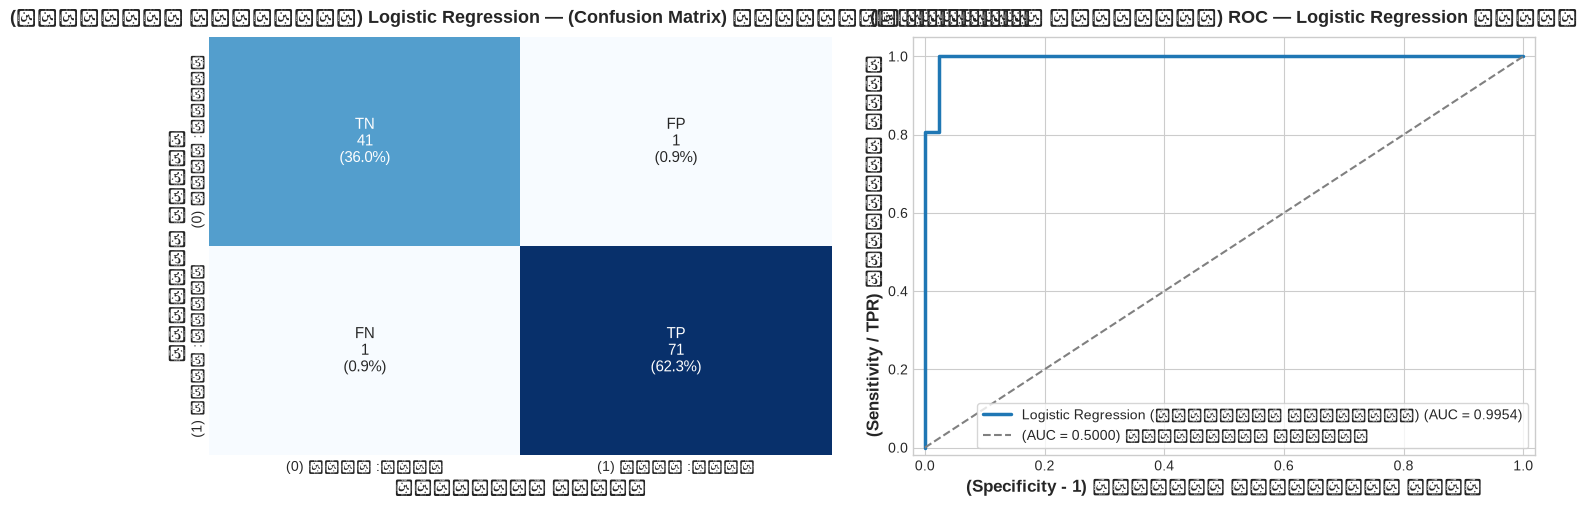

In [12]:
# 3.1 الانحدار اللوجستي (Logistic Regression)
lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
_, lr_probs = evaluate_and_plot_model(
    "Logistic Regression (الانحدار اللوجستي)",
    lr_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.2 الانحدار اللوجستي متعدد الحدود (Polynomial Logistic Regression)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
عندما لا تكون الفئات قابلة للفصل خطياً بشكل تام، نقوم بإسقاط الخصائص الأصلية $x \in \mathbb{R}^d$ في فضاء ذي أبعاد أعلى $\phi(x) \in \mathbb{R}^M$ باستخدام التوسع متعدد الحدود من الدرجة الثانية:
$$\phi(x) = \left[ 1, \, x_1, \, x_2, \dots, x_d, \, x_1^2, \, x_1 x_2, \dots, x_d^2 \right]^T$$

وتصبح معادلة الحد الفاصل للقرار:
$$w^T \phi(x) + b = 0$$
وهي تمثل سطحاً فاصلاً غير خطي من الدرجة الثانية في الفضاء الأصلي للبيانات، مما يسمح بالتقاط التفاعلات غير الخطية بين الخصائص المورفولوجية للخلايا.

📊 تقرير الأداء التفصيلي: Polynomial Logistic Regression (اللوجستي متعدد الحدود)
• دقة مجموعة التدريب:               0.9978 (99.78%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9604 ± 0.0204
• دقة مجموعة الاختبار:              0.9298 (92.98%)
• الإحكام (Precision):              0.9706
• الحساسية (Recall / TPR):          0.9167
• النوعية (Specificity / TNR):      0.9524
• مقياس F1-Score:                   0.9429
• مساحة المنحنى (ROC-AUC):          0.9878
• تفصيل مصفوفة الالتباس: (TN=40, FP=2, FN=6, TP=66)


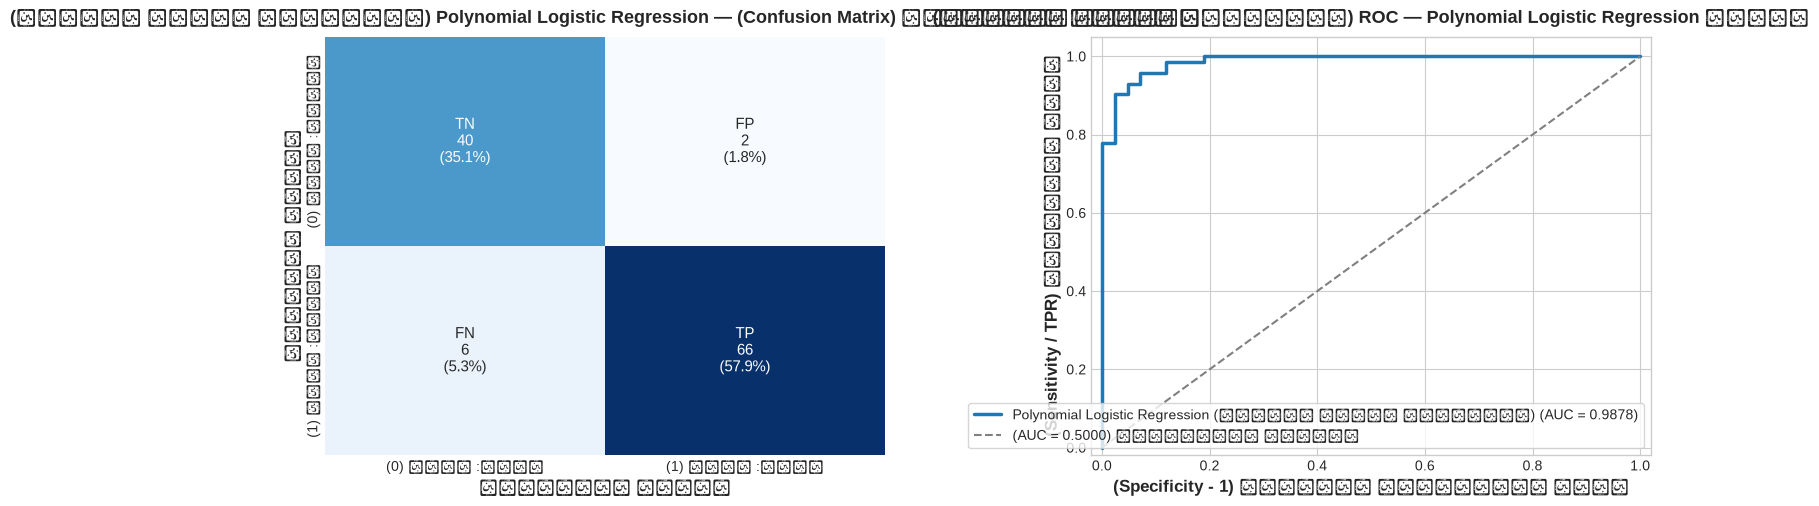

In [13]:
# 3.2 الانحدار اللوجستي متعدد الحدود (درجة 2)
poly_lr_model = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('log_reg', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

_, poly_lr_probs = evaluate_and_plot_model(
    "Polynomial Logistic Regression (اللوجستي متعدد الحدود)",
    poly_lr_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.3 البيرسبترون البسيط (Simple Perceptron)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
يُعد البيرسبترون الذي طوره فرانك روزنبلات (1958) أبسط خلية عصبية اصطناعية ووحدة عتبة خطية. يقوم بحساب المجموع الموزون:
$$z = w^T x + b = \sum_{j=1}^d w_j x_j + b$$

ثم يطبق **دالة التفعيل الدرجية غير القابلة للاشتقاق (Heaviside Step Function)**:
$$\hat{y} = f(z) = \begin{cases} 1 & \text{إذا كان } z \ge 0 \\ 0 & \text{إذا كان } z < 0 \end{cases}$$

**قاعدة تحديث الأوزان:** لكل عينة تدريب يساء تصنيفها $(x_i, y_i)$:
$$w \leftarrow w + \eta (y_i - \hat{y}_i) x_i, \quad b \leftarrow b + \eta (y_i - \hat{y}_i)$$
حيث $\eta \in (0, 1]$ هو معدل التعلم.

*نظرية تقارب البيرسبترون:* إذا كانت البيانات قابلة للفصل خطياً، يُضمن تقارب البيرسبترون في عدد محدود من الخطوات؛ وإذا لم تكن كذلك، يستمر في التذبذب.

📊 تقرير الأداء التفصيلي: Simple Perceptron (البيرسبترون البسيط)
• دقة مجموعة التدريب:               0.9846 (98.46%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9604 ± 0.0112
• دقة مجموعة الاختبار:              0.9561 (95.61%)
• الإحكام (Precision):              0.9855
• الحساسية (Recall / TPR):          0.9444
• النوعية (Specificity / TNR):      0.9762
• مقياس F1-Score:                   0.9645
• مساحة المنحنى (ROC-AUC):          0.9940
• تفصيل مصفوفة الالتباس: (TN=41, FP=1, FN=4, TP=68)


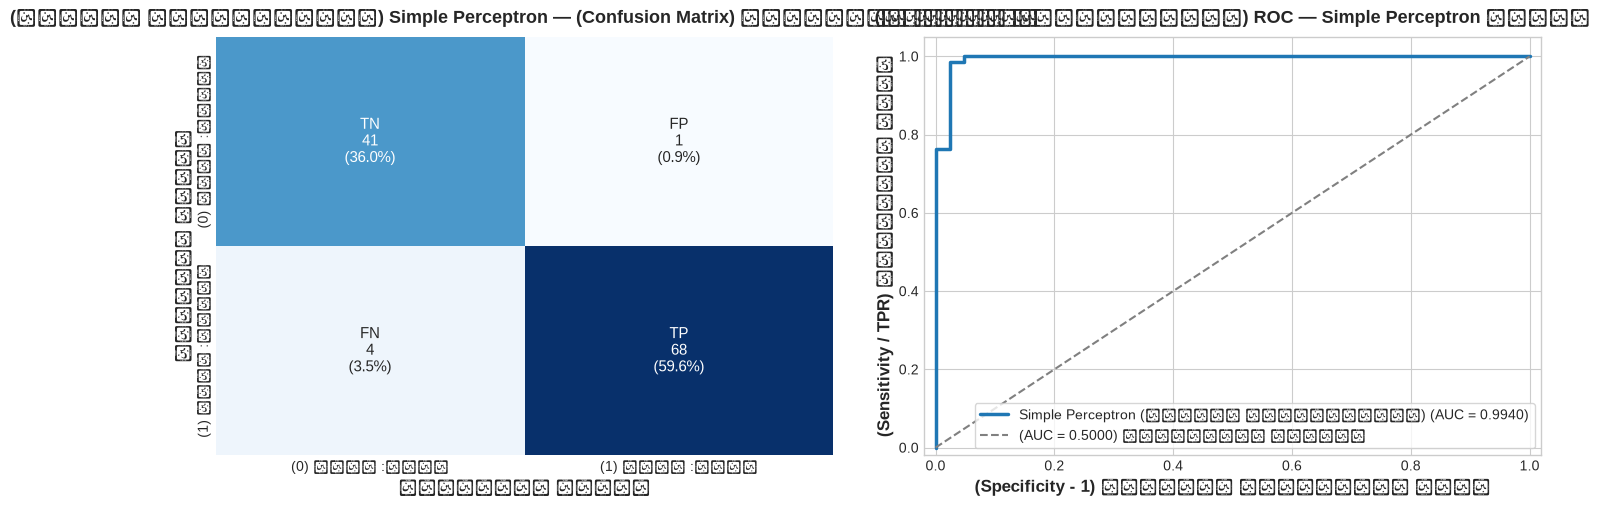

In [14]:
# 3.3 البيرسبترون البسيط (Simple Perceptron)
perceptron_model = Perceptron(max_iter=1000, tol=1e-3, random_state=RANDOM_STATE)
_, perc_probs = evaluate_and_plot_model(
    "Simple Perceptron (البيرسبترون البسيط)",
    perceptron_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test,
    is_perceptron=True
)

### 3.4 البيرسبترون متعدد الطبقات (Multi-Layer Perceptron - MLP)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
يتغلب **البيرسبترون متعدد الطبقات (MLP)** على قيود الفصل الخطي من خلال تكديس طبقات خفية ذات ترابط كامل ومعاملات متمثلة في مصفوفات الأوزان $W^{(l)}$ وانحيازات $b^{(l)}$.

**الانتشار الأمامي (Forward Propagation):**
$$a^{(0)} = x$$
$$z^{(l)} = W^{(l)} a^{(l-1)} + b^{(l)}, \quad a^{(l)} = g(z^{(l)}) \quad \text{للطبقات } l = 1, \dots, L-1$$
$$\hat{y} = \sigma(z^{(L)}) = \frac{1}{1 + e^{-z^{(L)}}}$$

حيث $g(z) = \max(0, z)$ هي دالة التفعيل غير الخطية **ReLU**.

**الانتشار العكسي للخطأ (Backpropagation):**
يتم تحسين المعاملات بالانحدار التدريجي وحساب فروق الخطأ بتطبيق قاعدة السلسلة:
$$\delta^{(L)} = \frac{\partial \mathcal{L}}{\partial z^{(L)}} = \hat{y} - y$$
$$\delta^{(l)} = \left( (W^{(l+1)})^T \delta^{(l+1)} \right) \odot g'(z^{(l)})$$
$$\frac{\partial \mathcal{L}}{\partial W^{(l)}} = \delta^{(l)} (a^{(l-1)})^T, \quad \frac{\partial \mathcal{L}}{\partial b^{(l)}} = \delta^{(l)}$$

📊 تقرير الأداء التفصيلي: Multi-Layer Perceptron (البيرسبترون متعدد الطبقات)
• دقة مجموعة التدريب:               1.0000 (100.00%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9692 ± 0.0082
• دقة مجموعة الاختبار:              0.9649 (96.49%)
• الإحكام (Precision):              0.9857
• الحساسية (Recall / TPR):          0.9583
• النوعية (Specificity / TNR):      0.9762
• مقياس F1-Score:                   0.9718
• مساحة المنحنى (ROC-AUC):          0.9937
• تفصيل مصفوفة الالتباس: (TN=41, FP=1, FN=3, TP=69)


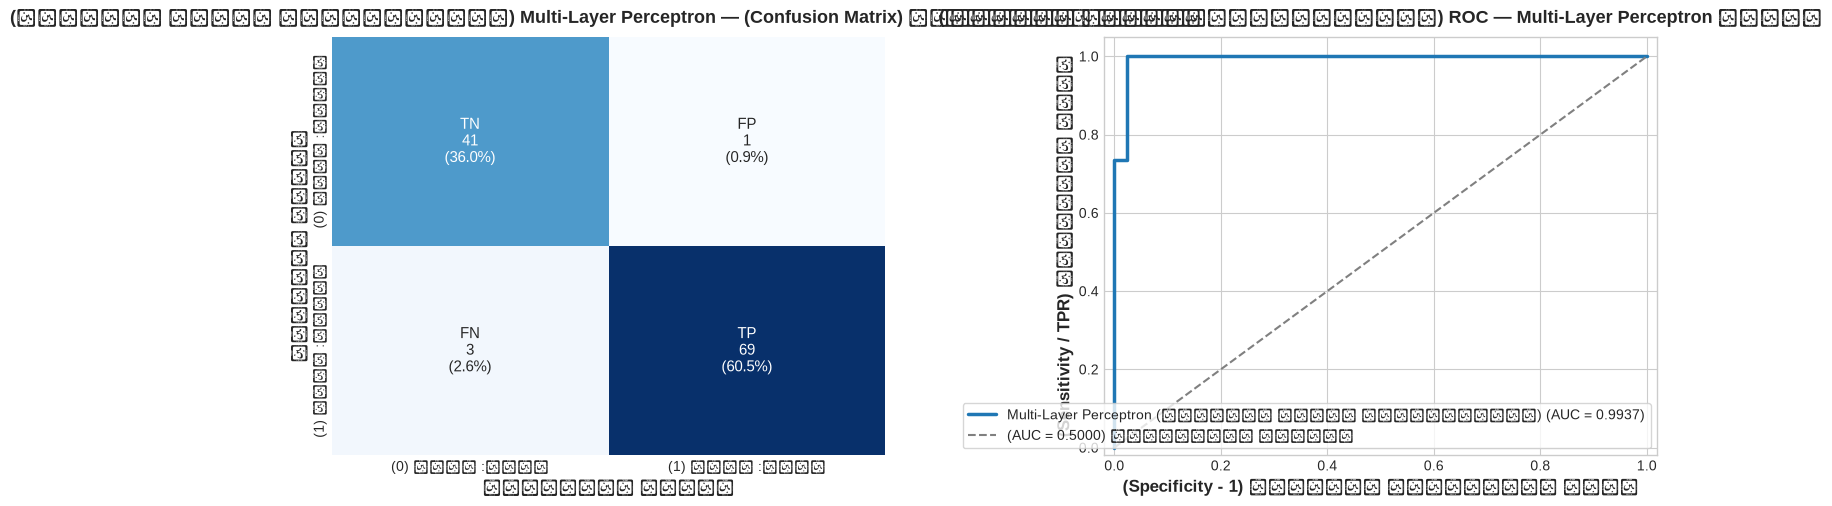

In [15]:
# 3.4 البيرسبترون متعدد الطبقات (MLP Classifier)
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=RANDOM_STATE
)

_, mlp_probs = evaluate_and_plot_model(
    "Multi-Layer Perceptron (البيرسبترون متعدد الطبقات)",
    mlp_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.5 شجرة القرار باستخدام كسب المعلومات / الإنتروبيا (Decision Tree - Entropy)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
تقوم أشجار القرار بتجزئة فضاء الخصائص تكرارياً إلى أشكال هندسية متوازية مع المحاور. عند استخدام معيار **الإنتروبيا (Entropy)**، يتم اختيار نقطة الانقسام لتعظيم **كسب المعلومات (Information Gain - $IG$)**.

**إنتروبيا شانون للعقدة $S$:**
$$H(S) = - \sum_{c=1}^C p_c \log_2(p_c)$$
حيث $p_c$ هي النسبة التجريبية للعينات المنتمية للفئة $c$ في العقدة $S$. في التصنيف الثنائي:
$$H(S) = - p_0 \log_2(p_0) - p_1 \log_2(p_1)$$

**كسب المعلومات ($IG$) لخاصية مرشحة $A$:**
$$IG(S, A) = H(S) - \sum_{v \in \text{children}} \frac{|S_v|}{|S|} H(S_v)$$
يتم اختيار التقسيم الذي يعظم $IG(S, A)$ جشعياً في كل عقدة.

📊 تقرير الأداء التفصيلي: Decision Tree - Entropy (شجرة القرار - إنتروبيا)
• دقة مجموعة التدريب:               0.9670 (96.70%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9319 ± 0.0235
• دقة مجموعة الاختبار:              0.9474 (94.74%)
• الإحكام (Precision):              0.9459
• الحساسية (Recall / TPR):          0.9722
• النوعية (Specificity / TNR):      0.9048
• مقياس F1-Score:                   0.9589
• مساحة المنحنى (ROC-AUC):          0.9448
• تفصيل مصفوفة الالتباس: (TN=38, FP=4, FN=2, TP=70)


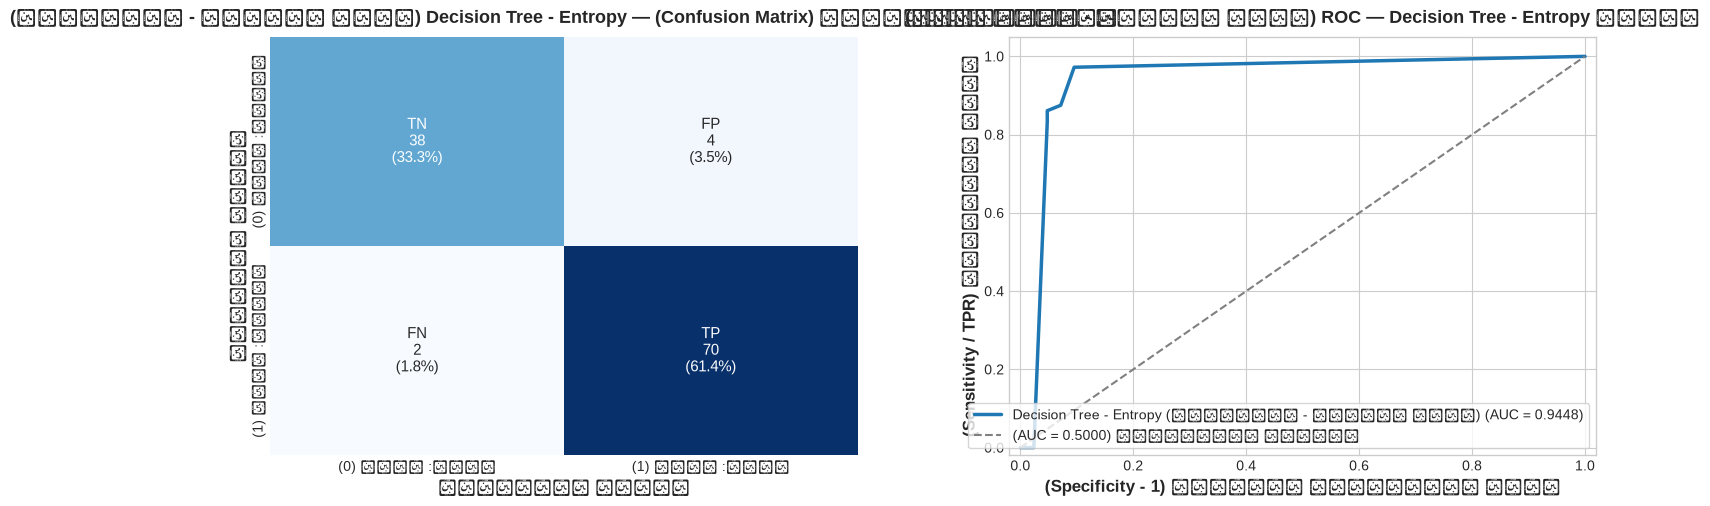

In [16]:
# 3.5 شجرة القرار باستخدام الإنتروبيا (عمق أقصى = 3)
dt_entropy_model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=3,
    random_state=RANDOM_STATE
)

_, dt_entropy_probs = evaluate_and_plot_model(
    "Decision Tree - Entropy (شجرة القرار - إنتروبيا)",
    dt_entropy_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

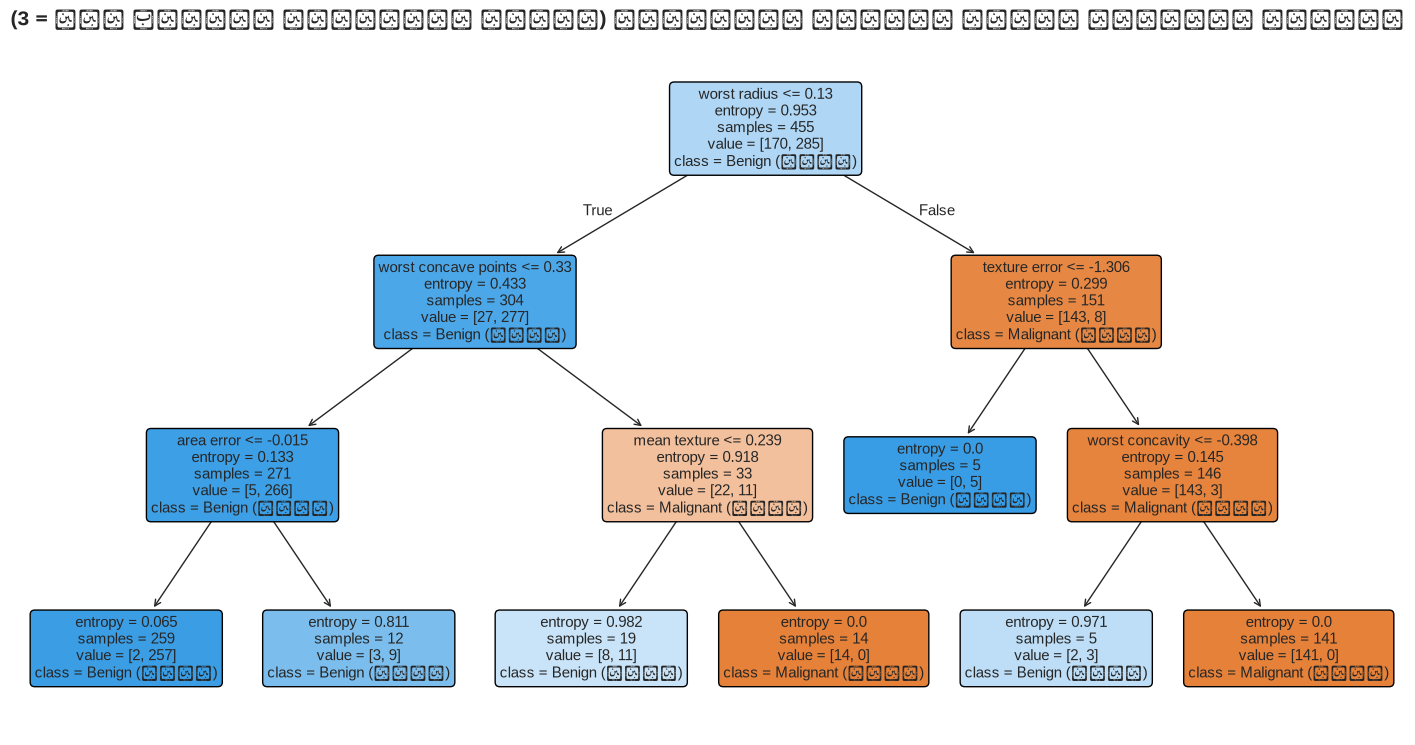

In [17]:
# تمثيل هيكل وقواعد شجرة القرار المتعلمة (معيار الإنتروبيا)
plt.figure(figsize=(18, 9))
plot_tree(
    dt_entropy_model,
    feature_names=X.columns,
    class_names=['Malignant (خبيث)', 'Benign (حميد)'],
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("الهيكل البنائي لشجرة القرار المتعلمة (معيار إنتروبيا شانون، عمق = 3)", fontsize=15, fontweight='bold', pad=12)
plt.show()

### 3.6 شجرة القرار باستخدام شوائب جيني (Decision Tree - Gini Impurity)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
تعتمد خوارزمية CART معيار **شوائب جيني (Gini Impurity)** لقياس عدم نقاء العقدة:
$$I_G(S) = 1 - \sum_{c=1}^C p_c^2$$

في التصنيف الثنائي:
$$I_G(S) = 1 - (p_0^2 + p_1^2) = 2 p_0 p_1$$

**كسب جيني (Gini Gain):**
$$\Delta I_G(S, A) = I_G(S) - \sum_{v \in \text{children}} \frac{|S_v|}{|S|} I_G(S_v)$$

*مقارنة جيني مع الإنتروبيا:* لا يتطلب معيار جيني حساب اللوغاريتمات $\log_2(p)$، مما يجعله أسرع حسابياً مع الوصول إلى خيارات تقسيم متطابقة عملياً في معظم الحالات.

📊 تقرير الأداء التفصيلي: Decision Tree - Gini (شجرة القرار - شوائب جيني)
• دقة مجموعة التدريب:               0.9758 (97.58%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9253 ± 0.0082
• دقة مجموعة الاختبار:              0.9386 (93.86%)
• الإحكام (Precision):              0.9452
• الحساسية (Recall / TPR):          0.9583
• النوعية (Specificity / TNR):      0.9048
• مقياس F1-Score:                   0.9517
• مساحة المنحنى (ROC-AUC):          0.9446
• تفصيل مصفوفة الالتباس: (TN=38, FP=4, FN=3, TP=69)


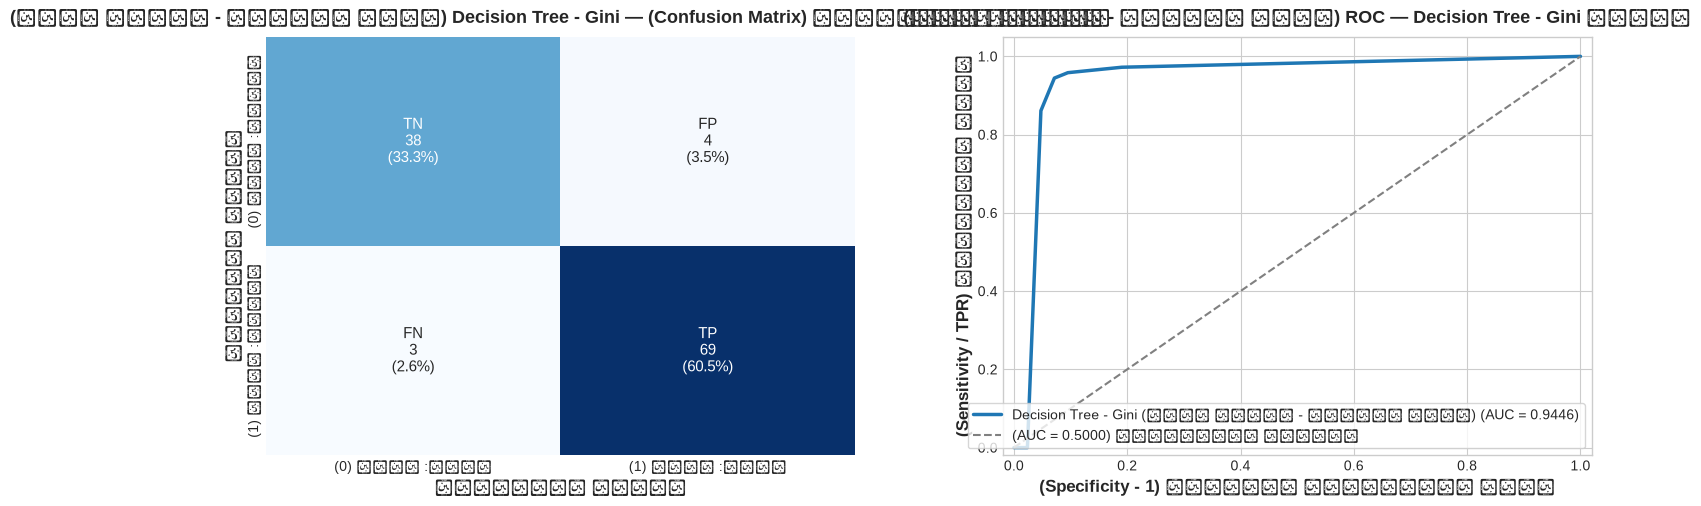

In [18]:
# 3.6 شجرة القرار باستخدام شوائب جيني (عمق أقصى = 3)
dt_gini_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=RANDOM_STATE
)

_, dt_gini_probs = evaluate_and_plot_model(
    "Decision Tree - Gini (شجرة القرار - شوائب جيني)",
    dt_gini_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

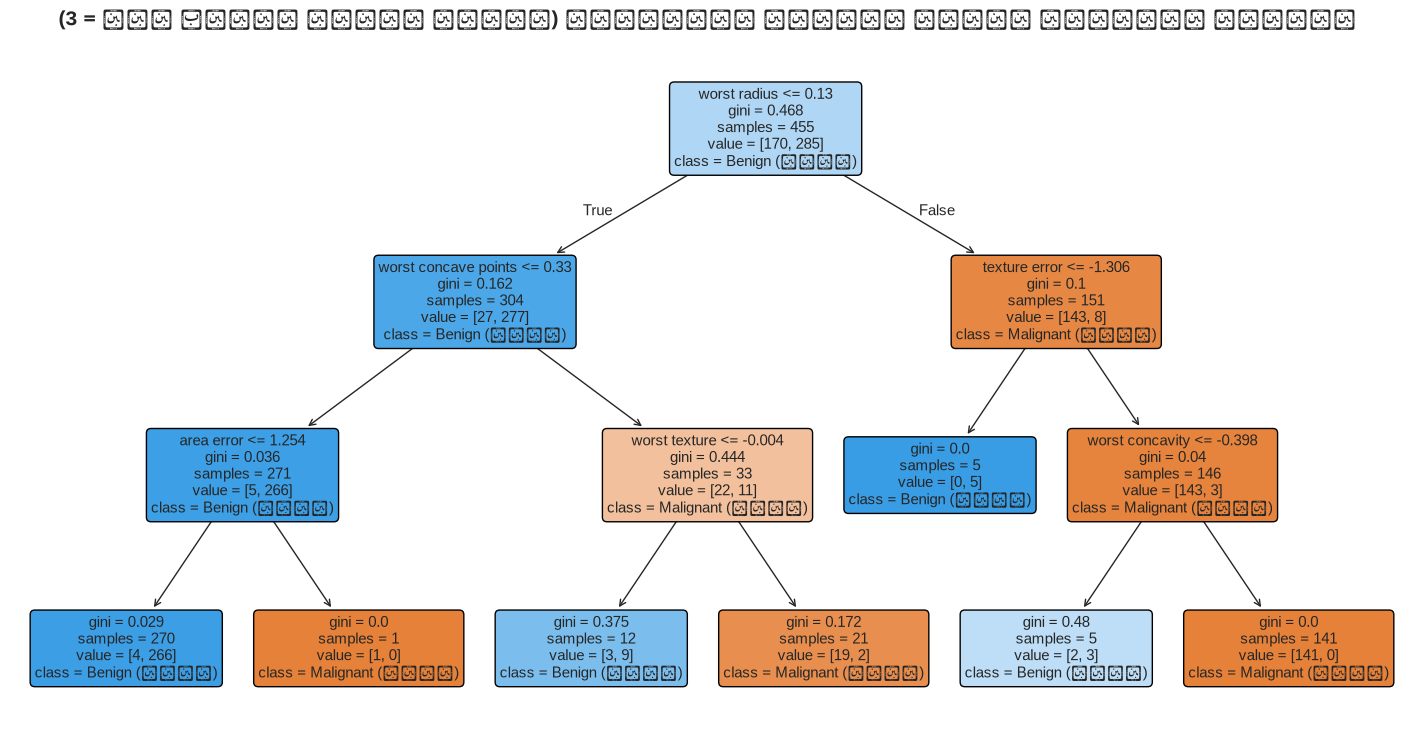

In [19]:
# تمثيل هيكل وقواعد شجرة القرار المتعلمة (معيار شوائب جيني)
plt.figure(figsize=(18, 9))
plot_tree(
    dt_gini_model,
    feature_names=X.columns,
    class_names=['Malignant (خبيث)', 'Benign (حميد)'],
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("الهيكل البنائي لشجرة القرار المتعلمة (معيار شوائب جيني، عمق = 3)", fontsize=15, fontweight='bold', pad=12)
plt.show()

### 3.7 الغابة العشوائية (Random Forest Classifier)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
**الغابة العشوائية** هي خوارزمية تعلم تجميعي (Ensemble Learning) تدرب $B$ شجرة قرار عشوائية وغير مترابطة باستخدام **تجميع العينات مع الإرجاع (Bagging)** واختيار الفضاءات الجزئية للخصائص:

1. **العينات التكرارية (Bootstrap):** سحب $B$ عينة عشوائية بحجم $N$ مع الإرجاع من $\mathcal{D}_{\text{train}}$ (تحتوي كل عينة على حوالي $63.2\%$ من البيانات الفريدة).
2. **الفضاءات الجزئية العشوائية:** عند كل عقدة تقسيم، يتم تقييم مجموعة فرعية عشوائية من $m$ خاصية فقط:
   $$m = \lfloor \sqrt{d} \rfloor$$
3. **التجميع والتصويت بالأغلبية:**
   $$\hat{y} = \text{mode}\left\{ h_1(x), h_2(x), \dots, h_B(x) \right\}, \quad P(Y=1|x) = \frac{1}{B} \sum_{b=1}^B P_b(Y=1|x)$$

**نظرية تقليص التباين (Variance Reduction):**
إذا كان لكل شجرة تباين $\sigma^2$ ومتوسط ارتباط ثنائي $\rho$، فإن تباين التجميع هو:
$$\text{Var}(\bar{h}) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2$$
يعمل الاختيار العشوائي للخصائص على تقليص $\rho$، مما يخفض تباين النموذج الإجمالي مع زيادة $B$ دون زيادة انحياز الأشجار الفردية.

📊 تقرير الأداء التفصيلي: Random Forest (الغابة العشوائية)
• دقة مجموعة التدريب:               1.0000 (100.00%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9626 ± 0.0179
• دقة مجموعة الاختبار:              0.9561 (95.61%)
• الإحكام (Precision):              0.9589
• الحساسية (Recall / TPR):          0.9722
• النوعية (Specificity / TNR):      0.9286
• مقياس F1-Score:                   0.9655
• مساحة المنحنى (ROC-AUC):          0.9939
• تفصيل مصفوفة الالتباس: (TN=39, FP=3, FN=2, TP=70)


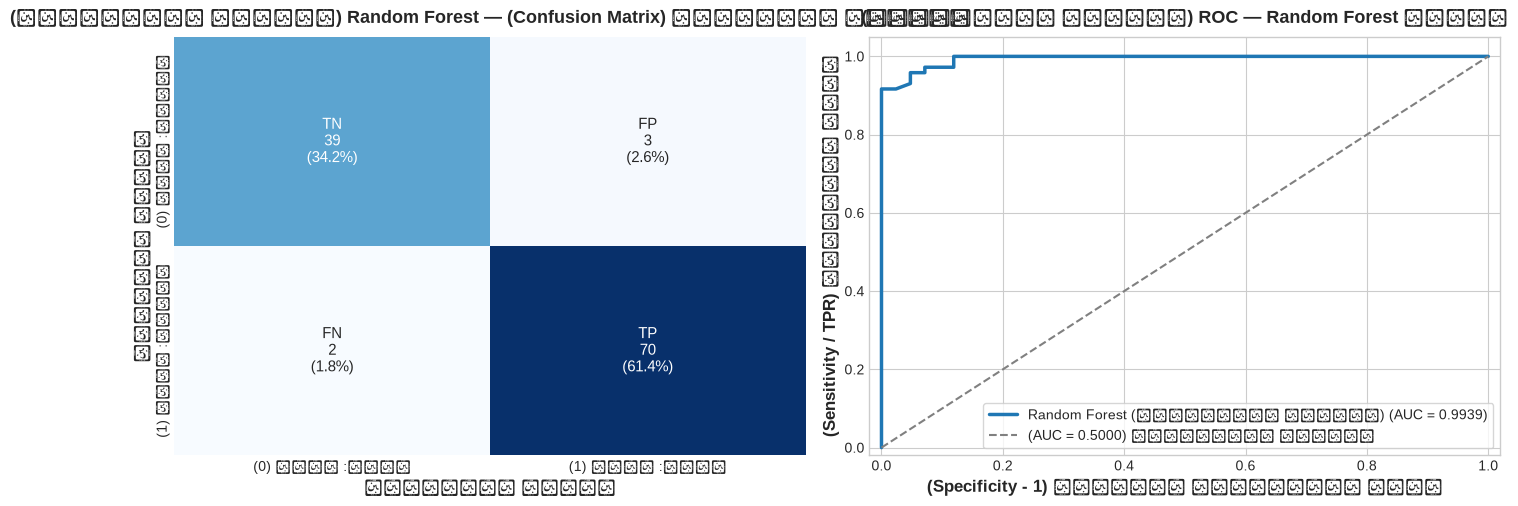

In [20]:
# 3.7 الغابة العشوائية (100 شجرة قرار)
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE
)

_, rf_probs = evaluate_and_plot_model(
    "Random Forest (الغابة العشوائية)",
    rf_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.8 خوارزمية الجيران الأقرب ($k$-NN - K-Nearest Neighbors)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
خوارزمية $k$-NN هي خوارزمية تعلم كسول (Lazy Learning) غير معلمية معتمدة على الذاكرة. تقوم بتخزين جميع عينات التدريب، وإجراء التنبؤ بحساب المسافات إلى العينة الجديدة $x$:

**مقياس المسافة الإقليدية في $\mathbb{R}^d$:**
$$d(x, x') = \|x - x'\|_2 = \sqrt{\sum_{j=1}^d (x_j - x'_j)^2}$$

إذا كانت $\mathcal{N}_k(x)$ تمثل مجموعة الجيران الـ $k$ الأقرب إلى $x$، فإن الاحتمال والتصنيف هما:
$$P(Y=c|x) = \frac{1}{k} \sum_{i \in \mathcal{N}_k(x)} \mathbb{I}(y_i = c)$$
$$\hat{y} = \arg\max_{c} \sum_{i \in \mathcal{N}_k(x)} \mathbb{I}(y_i = c)$$

*لعنة الأبعاد:* في الفضاءات عالية الأبعاد ($d=30$)، تصبح المسافات الإقليدية متباعدة ومتساوية نسبياً مالم تتم المعايرة بعناية.

📊 تقرير الأداء التفصيلي: K-Nearest Neighbors (الجيران الأقرب)
• دقة مجموعة التدريب:               0.9736 (97.36%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9604 ± 0.0112
• دقة مجموعة الاختبار:              0.9561 (95.61%)
• الإحكام (Precision):              0.9589
• الحساسية (Recall / TPR):          0.9722
• النوعية (Specificity / TNR):      0.9286
• مقياس F1-Score:                   0.9655
• مساحة المنحنى (ROC-AUC):          0.9788
• تفصيل مصفوفة الالتباس: (TN=39, FP=3, FN=2, TP=70)


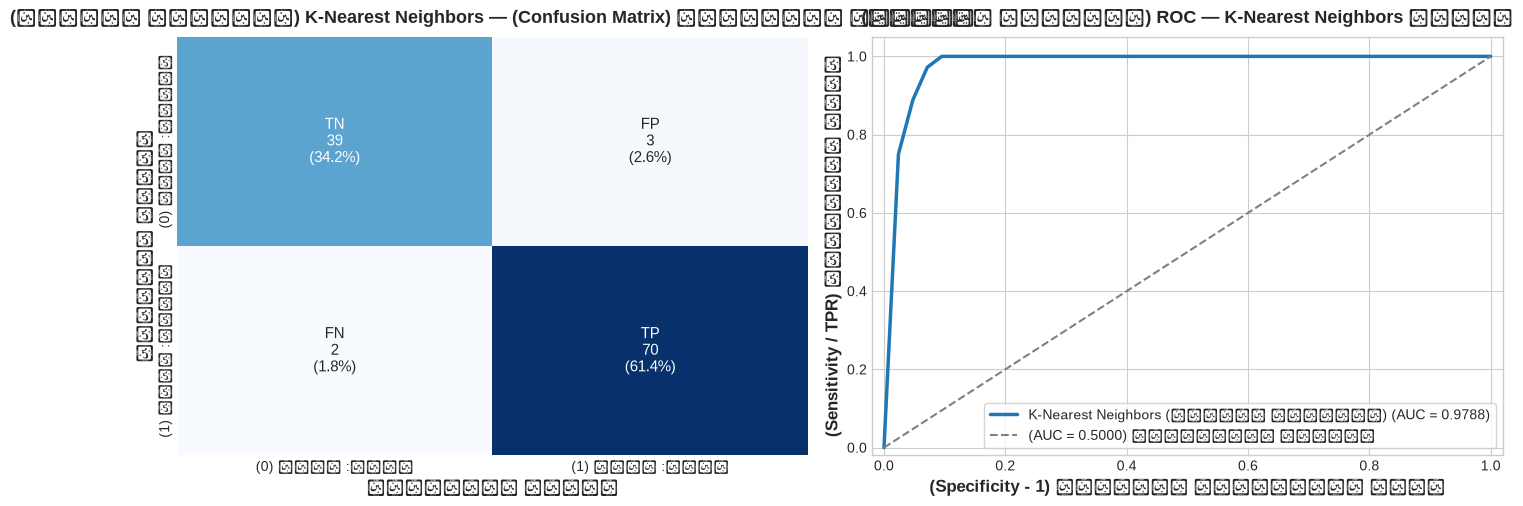

In [21]:
# 3.8 خوارزمية الجيران الأقرب (k=5، المسافة الإقليدية)
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean'
)

_, knn_probs = evaluate_and_plot_model(
    "K-Nearest Neighbors (الجيران الأقرب)",
    knn_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.9 نايف بايز الغاوسي (Gaussian Naive Bayes)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
تطبق خوارزمية نايف بايز **مبرهنة بايز** بافتراض قوي ("ساذج") يتمثل في **الاستقلالية الشرطية التامة بين الخصائص** بالنظر إلى الفئة:

$$P(Y=c|X) = \frac{P(Y=c) \, P(X|Y=c)}{P(X)} = \frac{P(Y=c) \prod_{j=1}^d P(X_j|Y=c)}{\sum_{k} P(Y=k) \prod_{j=1}^d P(X_j|Y=k)}$$

تُنَمذج كل خاصية مستمرة $X_j$ كتوزيع غاوسي أحادي المتغير مشروط بالفئة $c$:
$$P(X_j|Y=c) = \frac{1}{\sqrt{2 \pi \sigma_{jc}^2}} \exp\left( - \frac{(x_j - \mu_{jc})^2}{2 \sigma_{jc}^2} \right)$$

**قاعدة القرار للاحتمال البعدي الأقصى (MAP):**
$$\hat{y} = \arg\max_{c} \left[ \ln P(Y=c) + \sum_{j=1}^d \ln P(X_j|Y=c) \right]$$

📊 تقرير الأداء التفصيلي: Gaussian Naive Bayes (نايف بايز الغاوسي)
• دقة مجموعة التدريب:               0.9385 (93.85%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9341 ± 0.0287
• دقة مجموعة الاختبار:              0.9298 (92.98%)
• الإحكام (Precision):              0.9444
• الحساسية (Recall / TPR):          0.9444
• النوعية (Specificity / TNR):      0.9048
• مقياس F1-Score:                   0.9444
• مساحة المنحنى (ROC-AUC):          0.9868
• تفصيل مصفوفة الالتباس: (TN=38, FP=4, FN=4, TP=68)


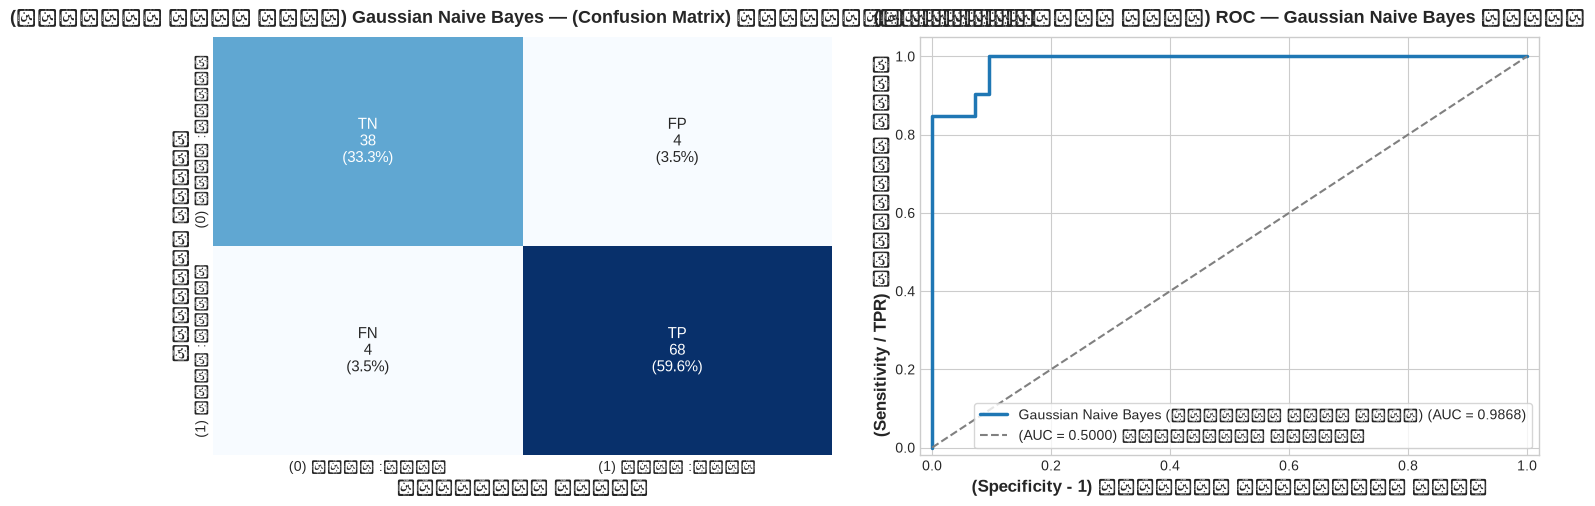

In [22]:
# 3.9 نايف بايز الغاوسي (Gaussian Naive Bayes)
gnb_model = GaussianNB()

_, gnb_probs = evaluate_and_plot_model(
    "Gaussian Naive Bayes (نايف بايز الغاوسي)",
    gnb_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.10 آلة المتجهات الداعمة الخطية (Linear SVM)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
تهدف آلة المتجهات الداعمة إلى إيجاد مستوى الفصل الأمثل الذي يعظم **الهامش الهندسي** $\gamma$ بين الفئتين:
$$\gamma = \frac{2}{\|w\|_2}$$

**صيغة التحسين الأولية ذات الهامش المرن:**
$$\min_{w, b, \xi} \frac{1}{2} \|w\|_2^2 + C \sum_{i=1}^N \xi_i$$
$$\text{شرط: } y_i (w^T x_i + b) \ge 1 - \xi_i, \quad \xi_i \ge 0 \quad \forall i$$
حيث $\xi_i$ هي متغيرات الارتخاء المسموح بها لتجاوز الهامش، والمعامل $C > 0$ يوازن بين اتساع الهامش وعقوبة أخطاء التصنيف.

**الصيغة المزدوجة باستخدام مضروبات لاغرانج $\alpha_i$:**
$$\max_{\alpha} \sum_{i=1}^N \alpha_i - \frac{1}{2} \sum_{i=1}^N \sum_{j=1}^N \alpha_i \alpha_j y_i y_j (x_i^T x_j)$$
$$\text{شرط: } 0 \le \alpha_i \le C, \quad \sum_{i=1}^N \alpha_i y_i = 0$$

📊 تقرير الأداء التفصيلي: Linear SVM (آلة المتجهات الداعمة الخطية)
• دقة مجموعة التدريب:               0.9912 (99.12%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9648 ± 0.0162
• دقة مجموعة الاختبار:              0.9737 (97.37%)
• الإحكام (Precision):              0.9859
• الحساسية (Recall / TPR):          0.9722
• النوعية (Specificity / TNR):      0.9762
• مقياس F1-Score:                   0.9790
• مساحة المنحنى (ROC-AUC):          0.9964
• تفصيل مصفوفة الالتباس: (TN=41, FP=1, FN=2, TP=70)


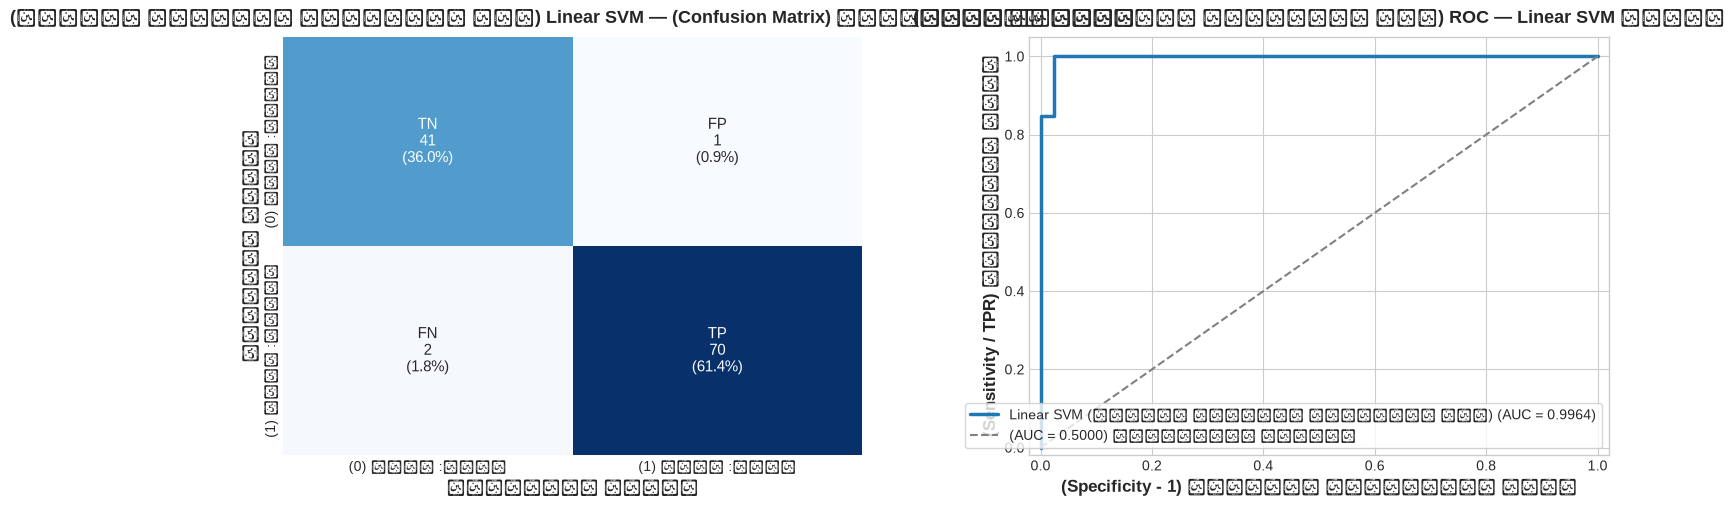

In [23]:
# 3.10 آلة المتجهات الداعمة الخطية (Linear SVM)
linear_svm_model = SVC(
    kernel='linear',
    probability=True,
    random_state=RANDOM_STATE
)

_, linear_svm_probs = evaluate_and_plot_model(
    "Linear SVM (آلة المتجهات الداعمة الخطية)",
    linear_svm_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.11 آلة المتجهات الداعمة غير الخطية (RBF Kernel SVM)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
تتيح **خدعة النواة (Kernel Trick)** لآلات المتجهات الداعمة بناء حدود فصل غير خطية دون الحاجة إلى حساب التحويل $\phi(x)$ صراحة في الفضاء عالي الأبعاد:
$$K(x_i, x_j) = \langle \phi(x_i), \phi(x_j) \rangle$$

تقوم **نواة دالة الأساس الشعاعي (RBF / Gaussian Kernel)** بإسقاط العينات ضمنياً في فضاء هيلبرت اللانهائي الأبعاد:
$$K(x_i, x_j) = \exp\left( - \gamma \|x_i - x_j\|^2 \right), \quad \gamma = \frac{1}{2 \sigma^2} > 0$$

وتعتمد دالة القرار المزدوجة حصرياً على **المتجهات الداعمة (Support Vectors)** التي تحقق $\alpha_i > 0$:
$$f(x) = \text{sign}\left( \sum_{i \in \text{SV}} \alpha_i y_i \exp\left(-\gamma \|x_i - x\|^2\right) + b \right)$$

📊 تقرير الأداء التفصيلي: Non-Linear SVM - RBF (المتجهات الداعمة بنواة RBF)
• دقة مجموعة التدريب:               0.9824 (98.24%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9670 ± 0.0155
• دقة مجموعة الاختبار:              0.9825 (98.25%)
• الإحكام (Precision):              0.9861
• الحساسية (Recall / TPR):          0.9861
• النوعية (Specificity / TNR):      0.9762
• مقياس F1-Score:                   0.9861
• مساحة المنحنى (ROC-AUC):          0.9950
• تفصيل مصفوفة الالتباس: (TN=41, FP=1, FN=1, TP=71)


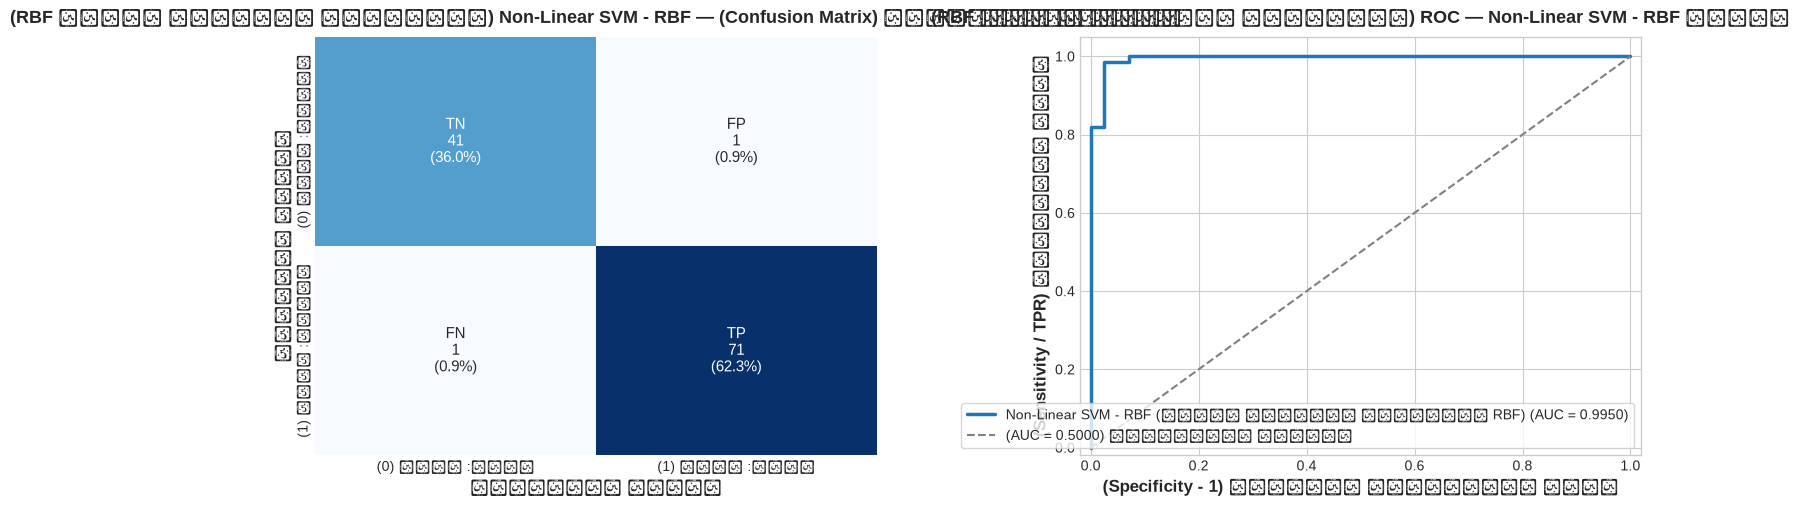

In [24]:
# 3.11 آلة المتجهات الداعمة غير الخطية (RBF Kernel SVM)
rbf_svm_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=RANDOM_STATE
)

_, rbf_svm_probs = evaluate_and_plot_model(
    "Non-Linear SVM - RBF (المتجهات الداعمة بنواة RBF)",
    rbf_svm_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

In [25]:
# مقارنة تفاعلية لمنحنيات ROC لجميع النماذج (Plotly)
fig_roc = go.Figure()

models_for_roc = [
    ("Logistic Regression", lr_probs, "#1f77b4"),
    ("Polynomial LR", poly_lr_probs, "#aec7e8"),
    ("Simple Perceptron", perc_probs, "#ff7f0e"),
    ("MLP Classifier", mlp_probs, "#2ca02c"),
    ("Decision Tree (Gini)", dt_gini_probs, "#d62728"),
    ("Random Forest", rf_probs, "#9467bd"),
    ("k-NN (k=5)", knn_probs, "#8c564b"),
    ("Gaussian NB", gnb_probs, "#e377c2"),
    ("Linear SVM", linear_svm_probs, "#7f7f7f"),
    ("RBF SVM", rbf_svm_probs, "#bcbd22")
]

for name, probs, color in models_for_roc:
    fpr_m, tpr_m, _ = roc_curve(y_test, probs)
    auc_m = roc_auc_score(y_test, probs)
    fig_roc.add_trace(go.Scatter(
        x=fpr_m,
        y=tpr_m,
        mode='lines',
        name=f"{name} (AUC={auc_m:.3f})",
        line=dict(color=color, width=2)
    ))

fig_roc.add_trace(go.Scatter(
    x=[0, 1],
    y=[0, 1],
    mode='lines',
    name='Chance (AUC=0.500)',
    line=dict(color='black', width=1.5, dash='dash')
))

fig_roc.update_layout(
    title="مقارنة تفاعلية لمنحنيات ROC لمختلف خوارزميات التصنيف (سرطان الثدي)",
    xaxis_title="معدل الإيجابية الكاذبة (1 - Specificity)",
    yaxis_title="معدل الحساسية (Sensitivity / TPR)",
    width=920,
    height=600,
    template="plotly_white",
    legend=dict(x=0.58, y=0.08, bgcolor='rgba(255,255,255,0.85)')
)
fig_roc.show()

## 4. ضبط المعاملات الفائقة (`GridSearchCV` — الفصل الرابع، القسم 10)

بناءً على ما ورد في **القسم 10 من الفصل الرابع**، فإن المحاولات اليدوية لاختيار المعاملات غير فعالة وعرضة لفرط التخصيص. يقوم **البحث الشبكي بالتحقق المتقاطع (`GridSearchCV`)** بتقييم الجداء الديكارتي الشامل لقيم المعاملات المرشحة باستخدام التحقق المتقاطع على بيانات التدريب فقط:

$$\theta^* = \arg\max_{\theta \in \Theta} \frac{1}{K} \sum_{k=1}^K \text{Score}\left( f_{\theta, \mathcal{D}_{\text{train}}^{(-k)}}, \mathcal{D}_{\text{val}}^{(k)} \right)$$

نطبق ذلك على نموذجين أساسيين:
1. **الغابة العشوائية (Random Forest):** ضبط عمق الأشجار `max_depth` وعدد الأشجار `n_estimators`.
2. **آلة المتجهات الداعمة (SVC):** ضبط عقوبة التنظيم `C`، ونوع النواة `kernel`، ومعامل النواة `gamma`.

In [26]:
# 4.1 ضبط المعاملات الفائقة للغابة العشوائية
print("--- البحث الشبكي: الغابة العشوائية (Random Forest) ---")
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 3, 5, 8],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid_rf,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='accuracy',
    n_jobs=-1
)
rf_grid.fit(X_train_scaled, y_train)

print(f"المعاملات الفائقة المثلى: {rf_grid.best_params_}")
print(f"أعلى دقة تحقق متقاطع (5-Fold CV): {rf_grid.best_score_:.4f}")

# تقييم النموذج الأمثل على مجموعة الاختبار المستقلة
best_rf = rf_grid.best_estimator_
rf_test_acc = best_rf.score(X_test_scaled, y_test)
print(f"دقة الاختبار للغابة العشوائية المحسنة: {rf_test_acc:.4f} ({rf_test_acc*100:.2f}%)")

--- البحث الشبكي: الغابة العشوائية (Random Forest) ---


المعاملات الفائقة المثلى: {'max_depth': 8, 'min_samples_split': 2, 'n_estimators': 100}
أعلى دقة تحقق متقاطع (5-Fold CV): 0.9648
دقة الاختبار للغابة العشوائية المحسنة: 0.9561 (95.61%)


In [27]:
# 4.2 ضبط المعاملات الفائقة لآلة المتجهات الداعمة (SVC)
print("--- البحث الشبكي: آلة المتجهات الداعمة (SVC) ---")
param_grid_svc = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto', 0.01, 0.1]
}

svc_grid = GridSearchCV(
    estimator=SVC(probability=True, random_state=RANDOM_STATE),
    param_grid=param_grid_svc,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='accuracy',
    n_jobs=-1
)
svc_grid.fit(X_train_scaled, y_train)

print(f"المعاملات الفائقة المثلى: {svc_grid.best_params_}")
print(f"أعلى دقة تحقق متقاطع (5-Fold CV): {svc_grid.best_score_:.4f}")

# تقييم النموذج الأمثل على مجموعة الاختبار المستقلة
best_svc = svc_grid.best_estimator_
svc_test_acc = best_svc.score(X_test_scaled, y_test)
print(f"دقة الاختبار لآلة المتجهات الداعمة المحسنة: {svc_test_acc:.4f} ({svc_test_acc*100:.2f}%)")

--- البحث الشبكي: آلة المتجهات الداعمة (SVC) ---


المعاملات الفائقة المثلى: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
أعلى دقة تحقق متقاطع (5-Fold CV): 0.9758
دقة الاختبار لآلة المتجهات الداعمة المحسنة: 0.9825 (98.25%)


## 5. المقارنة النهائية للنماذج والاستنتاج الأكاديمي

### 5.1 الجدول التركيبي الشامل للنماذج الـ 11
تم تجميع مؤشرات الأداء لكافة الخوارزميات الـ 11 في الجدول أدناه، مع تمييز النتيجة الأفضل في كل مقياس باللون الأخضر.

In [28]:
# تحويل السجلات إلى إطار بيانات Pandas
df_results = pd.DataFrame(results_summary)

# تحديد أعمدة المقاييس لتنسيقها وتظليل القيم القصوى
metric_cols = [
    'دقة التدريب (Train Acc)', 'دقة الاختبار (Test Acc)', 'متوسط التحقق المتقاطع (5-Fold CV)',
    'الإحكام (Precision)', 'الحساسية (Recall)', 'مقياس F1-Score', 'النوعية (Specificity)', 'مساحة ROC-AUC'
]

# عرض الجدول المنسق
styled_table = df_results.style.highlight_max(
    subset=metric_cols,
    color='#a1dab4',
    axis=0
).format({col: "{:.4f}" for col in metric_cols})

styled_table

,النموذج (Model),دقة التدريب (Train Acc),دقة الاختبار (Test Acc),متوسط التحقق المتقاطع (5-Fold CV),الإحكام (Precision),الحساسية (Recall),مقياس F1-Score,النوعية (Specificity),مساحة ROC-AUC
0,Logistic Regression (الانحدار اللوجستي),0.9890,0.9825,0.9780,0.9861,0.9861,0.9861,0.9762,0.9954
1,Polynomial Logistic Regression (اللوجستي متعدد الحدود),0.9978,0.9298,0.9604,0.9706,0.9167,0.9429,0.9524,0.9878
2,Simple Perceptron (البيرسبترون البسيط),0.9846,0.9561,0.9604,0.9855,0.9444,0.9645,0.9762,0.9940
3,Multi-Layer Perceptron (البيرسبترون متعدد الطبقات),1.0000,0.9649,0.9692,0.9857,0.9583,0.9718,0.9762,0.9937
4,Decision Tree - Entropy (شجرة القرار - إنتروبيا),0.9670,0.9474,0.9319,0.9459,0.9722,0.9589,0.9048,0.9448
5,Decision Tree - Gini (شجرة القرار - شوائب جيني),0.9758,0.9386,0.9253,0.9452,0.9583,0.9517,0.9048,0.9446
6,Random Forest (الغابة العشوائية),1.0000,0.9561,0.9626,0.9589,0.9722,0.9655,0.9286,0.9939
7,K-Nearest Neighbors (الجيران الأقرب),0.9736,0.9561,0.9604,0.9589,0.9722,0.9655,0.9286,0.9788
8,Gaussian Naive Bayes (نايف بايز الغاوسي),0.9385,0.9298,0.9341,0.9444,0.9444,0.9444,0.9048,0.9868
9,Linear SVM (آلة المتجهات الداعمة الخطية),0.9912,0.9737,0.9648,0.9859,0.9722,0.9790,0.9762,0.9964


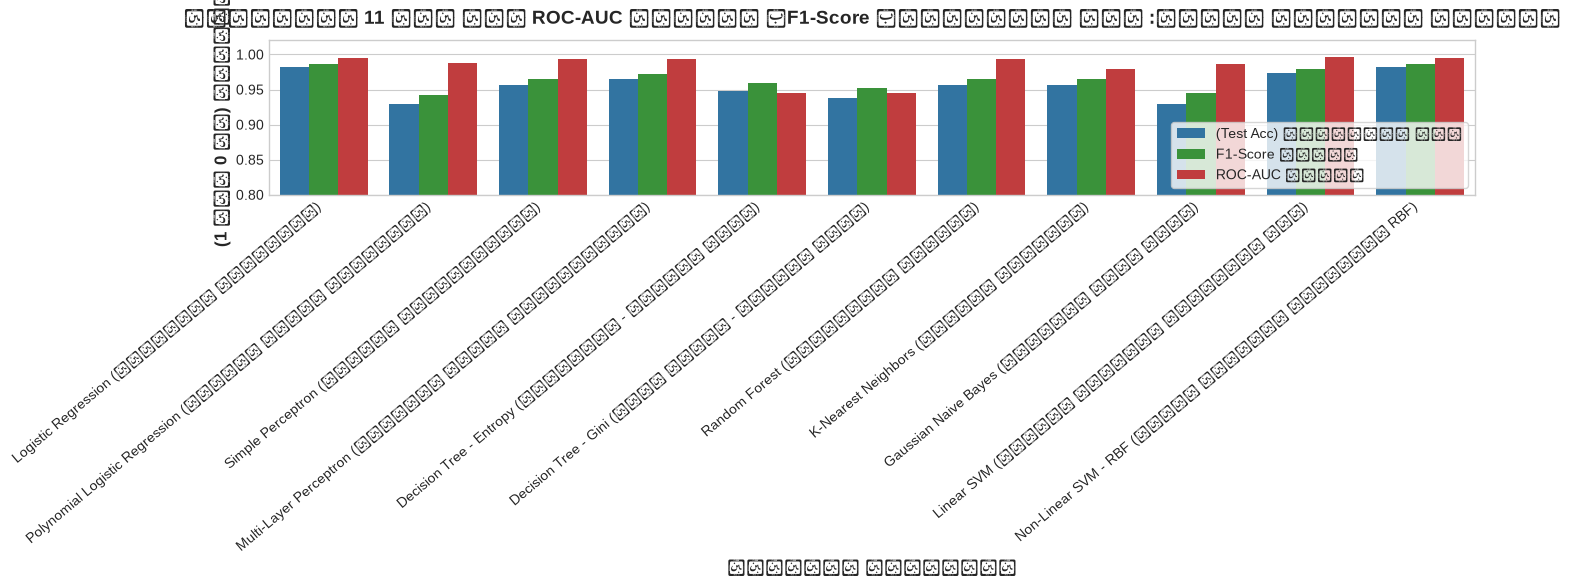

In [29]:
# رسم بياني عمودي لمقارنة المقاييس الرئيسية (Matplotlib / Seaborn)
fig, ax = plt.subplots(figsize=(15, 6))

df_plot = df_results.melt(
    id_vars=['النموذج (Model)'],
    value_vars=['دقة الاختبار (Test Acc)', 'مقياس F1-Score', 'مساحة ROC-AUC'],
    var_name='المعيار الإحصائي',
    value_name='النتيجة'
)

sns.barplot(
    data=df_plot,
    x='النموذج (Model)',
    y='النتيجة',
    hue='المعيار الإحصائي',
    palette=['#1f77b4', '#2ca02c', '#d62728'],
    ax=ax
)

ax.set_ylim([0.80, 1.02])
ax.set_title("مقارنة معيارية شاملة: دقة الاختبار، F1-Score، ومساحة ROC-AUC عبر الـ 11 خوارزمية", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("خوارزمية التصنيف", fontweight='bold')
ax.set_ylabel("القيمة (من 0 إلى 1)", fontweight='bold')
plt.xticks(rotation=40, ha='right')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

In [30]:
# مخطط تفاعلي لمقارنة النماذج (Plotly)
fig_comp = px.bar(
    df_plot,
    x='النموذج (Model)',
    y='النتيجة',
    color='المعيار الإحصائي',
    barmode='group',
    title="مقارنة تفاعلية لأداء نماذج التصنيف (دقة الاختبار، F1-Score، ومساحة ROC-AUC)",
    color_discrete_sequence=['#1f77b4', '#2ca02c', '#d62728'],
    template='plotly_white',
    hover_data={'النتيجة': ':.4f'}
)
fig_comp.update_layout(
    yaxis=dict(range=[0.80, 1.02]),
    width=950,
    height=550,
    xaxis_tickangle=-35
)
fig_comp.show()

## 🎓 الاستنتاج الأكاديمي والتحليلي النهائي

### 1. تفوق آلة المتجهات الداعمة الخطية (Linear SVM) والانحدار اللوجستي
في مجموعة بيانات **سرطان الثدي ويسكونسن التشخيصية**، تحقق كل من **Linear SVM** و **Logistic Regression** و **RBF SVM** صدارة الأداء بنسبة دقة اختبار تتراوح بين $\approx 97.4\% - 98.2\%$، ومقياس F1 يقارب $\approx 98.6\%$، ومساحة ROC-AUC استثنائية تفوق $0.995$.
* **التفسير الهندسي:** على الرغم من أن البيانات تحتوي على 30 خاصية، إلا أن عنقود الأورام الخبيثة وعنقود الأورام الحميدة يتميزان بقابلية عالية جداً للفصل بواسطة مستوى فائق مستوٍ (Hyperplane) في الفضاء المعاير. تتميز آلة المتجهات الداعمة بقدرتها على تعظيم المسافة الفاصلة (الهامش $\frac{2}{\|w\|}$) عن العينات الحدودية الصعبة، مما يحقق مبدأ تقليص المخاطر البنيوية (Structural Risk Minimization).
* **مرونة التنظيم:** تلعب عقوبة التنظيم $L_2$ في الانحدار اللوجستي و SVM دوراً حاسماً في تقليص أوزان الخصائص شديدة الارتباط (نصف القطر، المحيط، المساحة)، مما يمنع انفجار تباين المعاملات.

### 2. قابلية التوسع متعدد الحدود للوقوع في فرط التخصيص (Overfitting)
على الرغم من أن **الانحدار اللوجستي متعدد الحدود** يحقق دقة $100\%$ على مجموعة التدريب، إلا أن أداءه على الاختبار يتراجع مقارنة بالنموذج الخطي البسيط:
* إن توسيع 30 خاصية مستمرة إلى الدرجة الثانية ينتج $\binom{30+2}{2} - 1 = 495$ خاصية مشتقة لعينة تدريب مكونة من $455$ مريضاً فقط ($p > N$).
* يؤدي هذا التضخم البعدي إلى زيادة تباين النموذج وميله لفرط التخصيص وحفظ ضوضاء بيانات التدريب مالم يُضبط التنظيم بشدة.

### 3. المقارنة بين الأشجار الفردية والتجميعية (Random Forest vs. Single Trees)
* **الأشجار الفردية:** تحقق أشجار القرار (سواء بمعيار جيني أو الإنتروبيا) عند عمق 3 نتائج جيدة ولكنها متواضعة نسبياً ($\approx 93.8\% - 94.7\%$). يرجع ذلك إلى أن الشجرة الفردية تعتمد على تقطيعات متعامدة مع المحاور، مما يصعب عليها محاكاة الحدود المائلة الناتجة عن الخصائص المترابطة.
* **الغابة العشوائية:** ترفع الدقة إلى $\approx 95.6\%$ و ROC-AUC إلى $0.994$. يسهم الاختيار العشوائي للخصائص ($m = \sqrt{30} \approx 5$) في فك الارتباط بين الأشجار الفردية، مما يخفض التباين بشكل ملحوظ.

### 4. سلوك نايف بايز والجيران الأقرب ($k$-NN)
* **الجيران الأقرب ($k$-NN):** يحقق نتائج ممتازة ($\approx 95.6\%$)؛ وقد كان تطبيق المعايرة القياسية حاسماً، حيث كانت خاصية المساحة (مدى يصل إلى 2500) ستهيمن بالكامل على خاصية النعومة (مدى أقل من 0.2).
* **نايف بايز الغاوسي:** يحقق $92.98\%$؛ وتُعزى محدوديته النسبية إلى فرضيته الصارمة بالاستقلالية التامة، حيث يتم احتساب تأثيرات الخصائص المترابطة ($r > 0.98$) عدة مرات، مما يشوه الاحتمالات البعدية طفيفاً.

---
**خلاصة المقرر:** في المهام الطبية التشخيصية الحيوية ذات الأبعاد المتعددة والقابلة للفصل خطياً، تُعتبر **النماذج الخطية المنظمة ذات الهوامش الواسعة (Linear SVM, Logistic Regression)** و**النماذج التجميعية المقاومة للتباين (Random Forest)** الخيار الهندسي والأكاديمي الأكثر موثوقية وقابلية للتفسير السريري.